# Does a bigger language model make a contents page more useful?

This notebook evaluates whether increasing model size improves structured section retrieval on the STAIR benchmark, comparing FLAN-T5-small, Qwen3.5-2B, and Qwen3.5-4B on an accounting textbook corpus.

Key findings from the matched 4B evaluation:
- **Flat catalogue upgrade:** Constrained Recall@1 shifts slightly from **66.14% (2B) to 66.93% (4B)** (+0.79 pp, 95% cluster interval [-9.24, +11.03]).
- **Hierarchical catalogue:** Reaches **67.72%** (+0.79 pp over flat 4B), but this difference disappears in sensitivity checks.
- **Compute cost:** The 4B D/E/F parameter and checkpoint search required **10.41 hours versus 4.17 hours for 2B (2.49×)**.

**Execution mode:** Running this notebook executes an offline replay: it verifies SHA-256 manifests, loads stored prediction outputs, recomputes metrics and paired confidence intervals, and exports publication-ready tables and figures without loading model weights.

# Setup

Run this notebook in the `.venv-stair` Python environment. Stored run artifacts are located in `runs/stair/`. All calculation and plotting helpers are self-contained inline.

Tables and figures are rendered via Matplotlib and exported to `graphs/` as `stair_table_*.png` and `stair_graph_*.png` without embedded title banners.

In [2]:
# Standard library
from collections import Counter
import hashlib
import io
import json
import math
import os
from pathlib import Path
import textwrap
import unicodedata

# CPU analysis, PNG tables and display only
os.environ.setdefault("MPLCONFIGDIR", str(Path(os.environ.get("STAIR_ROOT", ".")).resolve() / "data/stair/mpl-cache"))
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, Image, Markdown, display

class CFG:
    MODE = "report"
    ROOT = Path(os.environ.get("STAIR_ROOT", ".")).resolve()
    RUNS = {'4b': 'runs/stair/qwen-4b-pilots/recovery-20261108T082822851692Z', '2b': 'runs/stair/qwen-2b-pilots/pilot-20261107T123438089920Z'}
    SEAL_HASHES = {'4b': '7a55b439026f288b41296a6eaf75a715018d3bfaa21f00d7e5ca006ee29aa28c', '2b': '6d878dc5d0fc09d805835abe48b43bb02065dd740ef69b9cd35819951135e412'}
    GRAPHS = ROOT / "graphs"
    ASSET_PLAN = [('table', 'Frozen cohorts and candidate documents'), ('table', 'Retrieval methods and their information'), ('table', 'Captured lexical baselines'), ('table', 'Loaded model sizes and admitted batches'), ('table', 'Selected checkpoints and search costs'), ('graph', 'Captured tuning curves'), ('table', 'Matched development Recall at rank one'), ('table', 'Full-budget rank metrics'), ('graph', 'Matched accuracy and unconstrained invalidity'), ('table', 'Unconstrained title validity'), ('table', 'Paired effects and ambiguity sensitivity'), ('table', 'Training support and catalogue conditioning'), ('table', 'Full-budget search and constrained inference costs'), ('table', 'Captured resource counters'), ('table', 'Memory interruption and exact recovery')]
    img_dim1 = 14
    export_dpi = 180
    model_seed = 42
    order_seed = 42002
    bootstrap_seed = 42001
    bootstrap_replicates = 10000

plt.style.use("seaborn-v0_8")
print("Offline report only: zero new model calls; evidence root:", CFG.ROOT)

Offline report only: zero new model calls; evidence root: /private/tmp/stair-current-report-d5_uugyo


Configuration pins the source run directories and manifest hashes for reproducible offline replay.

# Utils

## Metrics with the original rank slots

In [3]:
def canonical(value):
    return " ".join(unicodedata.normalize("NFC", value).split())

def score(records, queries, corpus):
    ids = {canonical(row["title"]): f"finance:{index:03d}" for index, row in enumerate(corpus)}
    gold = {row["query_id"]: row["gold_title"] for row in queries}
    if len(records) != len(gold) or {row["query_id"] for row in records} != set(gold):
        raise ValueError("Missing/duplicate/mismatched raw predictions")
    result = {}
    for record in records:
        target = ids[gold[record["query_id"]]]
        positions = [rank for rank, hypothesis in enumerate(record["hypotheses"][:3], 1)
                     if hypothesis.get("section_id") == target]
        rank = min(positions) if positions else None
        first = record["hypotheses"][0] if record["hypotheses"] else {}
        result[record["query_id"]] = {
            "gold_title": gold[record["query_id"]], "r1": int(rank == 1),
            "r3": int(rank is not None), "ndcg3": 1 / math.log2(rank + 1) if rank is not None else 0.,
            "invalid1": int(first.get("validity") != "valid")}
    return result

def summary(scored):
    return {"queries": len(scored), **{key: float(np.mean([row[key] for row in scored.values()]))
            for key in ["r1", "r3", "ndcg3", "invalid1"]}}

def query_seconds(records):
    if "timing" not in records[0]:
        return sum(row["elapsed_seconds"] for row in records) / len(records)
    elapsed, index = 0., 0
    while index < len(records):
        timing = records[index]["timing"]
        elapsed += timing["end_to_end_seconds"]
        index += timing["batch_size"]
    return elapsed / len(records)

Functions to evaluate Recall@1, Recall@3, and nDCG@3 against gold section targets. Ranks and invalid-prediction penalties match the study contract; query latencies reflect recorded benchmark timings.

## Paired uncertainty

In [4]:
def clustered(delta, gold):
    labels = sorted(set(gold))
    gold = np.array(gold)
    delta = np.array(delta, dtype=float)
    sums = np.array([delta[gold == label].sum() for label in labels])
    counts = np.array([(gold == label).sum() for label in labels])
    sample = np.random.default_rng(42001).integers(0, len(labels), (10000, len(labels)))
    estimate = sums[sample].sum(1) / counts[sample].sum(1)
    lo, hi = np.quantile(estimate, [.025, .975]) * 100
    return {"difference_pp": float(delta.mean() * 100), "ci95_pp": [float(lo), float(hi)],
            "queries": len(delta), "document_clusters": len(labels), "unstable_small_support": len(labels) < 10,
            "interval_scope": "exploratory paired released-document-cluster interval, one book/seed"}

def compare(left, right):
    if set(left) != set(right):
        raise ValueError("Pairing changed")
    ids = sorted(left)
    a = np.array([left[key]["r1"] for key in ids])
    b = np.array([right[key]["r1"] for key in ids])
    return clustered(b - a, [left[key]["gold_title"] for key in ids]) | {
        "gains": int(((a == 0) & (b == 1)).sum()), "losses": int(((a == 1) & (b == 0)).sum()),
        "both_right": int(((a == 1) & (b == 1)).sum()), "both_wrong": int(((a == 0) & (b == 0)).sum())}

Calculates paired differences on identical queries and computes 95% bootstrap confidence intervals across document clusters using 10,000 resamples (seed 42001).

## Seals, membership and raw-evidence replay

In [5]:
def load_evidence(root, runs, seal_hashes):
    """Verify consumed bytes and recompute all captured metrics and paired effects."""
    root = Path(root).resolve()
    seals, consumed, objects = {}, {}, {}
    for name, relative in runs.items():
        path = root / relative / "pilot_manifest.json"
        raw = path.read_bytes()
        if hashlib.sha256(raw).hexdigest() != seal_hashes[name]:
            raise ValueError(f"Pinned {name} seal changed: {path}")
        seals[name] = json.loads(raw)
        if seals[name]["validation"]["status"] != "passed":
            raise ValueError("Source experiment is not validated")

    def checked(name, relative, as_bytes=False):
        entry = seals[name]["files"][relative]
        path = root / runs[name] / relative
        raw = path.read_bytes()
        if hashlib.sha256(raw).hexdigest() != entry["sha256"]:
            raise ValueError(f"Changed evidence: {path}")
        consumed[str(Path(runs[name]) / relative)] = entry["sha256"]
        if as_bytes:
            return raw
        if relative.endswith(".jsonl"):
            return [json.loads(line) for line in raw.decode().splitlines() if line.strip()]
        return json.loads(raw)

    data = checked("4b", "inputs.json")
    if data != checked("2b", "inputs.json"):
        raise ValueError("2B and 4B cohort membership differs")
    if [len(data[k]) for k in ["train935", "tune", "screen", "corpus"]] != [935, 48, 127, 86]:
        raise ValueError("Unexpected study dimensions")
    train_ids, tune_ids, screen_ids = [set(r["query_id"] for r in data[k]) for k in ["train935", "tune", "screen"]]
    if train_ids & tune_ids or train_ids & screen_ids or tune_ids & screen_ids:
        raise ValueError("Train/tune/screen membership overlaps")
    reserve = checked("4b", "confirmation_reserve.json")
    reserve_ids = set(reserve["ids"])
    if len(reserve_ids) != 240 or reserve["model_predictions"] != 0:
        raise ValueError("Future confirmation boundary changed")
    if (train_ids | tune_ids | screen_ids) & reserve_ids:
        raise ValueError("Reserve membership overlaps the reported study")
    audit = checked("4b", "source_audit.json")
    if audit["confirmed_multi_leaf_documents"] != 9:
        raise ValueError("Source-boundary interpretation changed")
    flags = {r["query_id"] for r in checked("4b", "screen_semantic_audit.json")["rows"] if r["status"] != "supported"}
    if len(flags) != 3:
        raise ValueError("Annotation sensitivity changed")
    captured = checked("4b", "quality/analysis.json")
    definitions = {"qwen4b": checked("4b", "quality/cells.json"),
                   "qwen2b": checked("2b", "quality/cells.json"),
                   "flan": checked("4b", "flan_baseline/result.json")["cells"]}
    frames, recomputed, prediction_rows = {}, {}, 0
    for family, cells in definitions.items():
        name = "2b" if family == "qwen2b" else "4b"
        folder = "flan_baseline" if family == "flan" else "quality"
        for cell in cells:
            for mode in ["constrained", "unconstrained"]:
                rows = checked(name, f"{folder}/predictions/{cell}/{mode}.jsonl")
                if any(r["query_id"] in reserve_ids for r in rows):
                    raise ValueError("Reserve prediction detected")
                for row in rows:
                    for hypothesis in row["hypotheses"]:
                        if len(hypothesis["token_ids"]) != len(hypothesis["token_logprobs"]):
                            raise ValueError("Token-score lengths differ")
                        if not np.isclose(np.mean(hypothesis["token_logprobs"]), hypothesis["score"], atol=1e-3, rtol=1e-3):
                            raise ValueError("Mean beam score reconstruction failed")
                key = (family, cell, mode)
                frames[key] = score(rows, data["screen"], data["corpus"])
                recomputed[key] = summary(frames[key]) | {"query_seconds": query_seconds(rows)}
                prediction_rows += len(rows)
    lexical = checked("4b", "flan_baseline/lexical/lexical.jsonl")
    for method in "AB":
        rows = [r for r in lexical if r["method"] == method]
        key = ("lexical", method, "lexical")
        frames[key] = score(rows, data["screen"], data["corpus"])
        recomputed[key] = summary(frames[key]) | {"query_seconds": query_seconds(rows)}
        prediction_rows += len(rows)
    if len(recomputed) != len(captured["metrics"]):
        raise ValueError("Missing metric rows")
    for row in captured["metrics"]:
        key = (row["family"], row["cell"], row["mode"])
        for field, value in recomputed[key].items():
            if value != row[field]:
                raise ValueError(f"Metric differs from sealed report: {key}, {field}")
        sensitivity = summary({qid: r for qid, r in frames[key].items() if qid not in flags})
        if key[0] != "lexical" and sensitivity["r1"] != row["sensitivity_r1"]:
            raise ValueError("Sensitivity metric differs")
    for effect in captured["effects"]:
        left, right = [frames[tuple(effect[side])] for side in ["left", "right"]]
        paired = compare(left, right)
        for field, value in paired.items():
            if value != effect[field]:
                raise ValueError(f"Paired effect differs: {effect['contrast']}, {field}")
        ids = sorted(left)
        invalid = clustered([right[i]["invalid1"] - left[i]["invalid1"] for i in ids], [left[i]["gold_title"] for i in ids])
        sensitivity = compare({i: r for i, r in left.items() if i not in flags}, {i: r for i, r in right.items() if i not in flags})
        if (invalid["difference_pp"] != effect["invalid_change_pp"] or invalid["ci95_pp"] != effect["invalid_ci95_pp"]
                or sensitivity["difference_pp"] != effect["sensitivity_difference_pp"]):
            raise ValueError("Effect validity/sensitivity differs")
    costs, selections, contracts, models = [], [], {}, {}
    for name, family in [("2b", "qwen2b"), ("4b", "qwen4b")]:
        contracts[family] = checked(name, "quality/execution_contract.json")
        models[family] = checked(name, "quality/model_loading.json")
        for trajectory in checked(name, "quality/trajectories.json"):
            fmt, history = trajectory["method"], trajectory["history"]
            if [r["update"] for r in history] != list(range(32, 385, 32)):
                raise ValueError("Incomplete tuning trajectory")
            for budget in [128, 384]:
                selected = max((r for r in history if r["update"] <= budget), key=lambda r: (r["tune_r1"], -r["update"]))
                definition = definitions[family][f"n935_u{budget}_{fmt}"]
                seconds = sum(sum(r[k] for k in ["training_seconds", "tuning_seconds", "checkpoint_seconds"]) for r in history if r["update"] <= budget)
                if selected != trajectory["selected"][str(budget)] or definition["selected_update"] != selected["update"]:
                    raise ValueError("Checkpoint selection changed")
                if definition["training_seconds"] != seconds:
                    raise ValueError("Recorded search cost changed")
                selections.append({"Model": family, "Method": fmt, "Search budget": budget,
                                   "Selected update": selected["update"], "Tuning R@1 (%)": 100 * selected["tune_r1"],
                                   "Fit/tune/save (h)": seconds / 3600})
            costs.append({"Model": family, "Method": fmt, "Fit/tune/save (h)": seconds / 3600,
                          "Constrained s/query": recomputed[(family, f"n935_u384_{fmt}", "constrained")]["query_seconds"]})
    for name in ["comparison.png", "tuning.png"]:
        objects[name] = checked("4b", "quality/figures/" + name, as_bytes=True)
    evidence = {"analysis": captured, "frames": frames, "metrics": recomputed, "data": data,
                "flags": flags, "audit": audit, "costs": costs, "selections": selections,
                "contracts": contracts, "models": models, "figures": objects,
                "validation": checked("4b", "quality/validation.json"),
                "stages": checked("4b", "stage_reports.json"),
                "consumed_files": consumed, "source_seals": seal_hashes,
                "proof": {"metric_rows_recomputed": len(recomputed), "paired_effects_recomputed": len(captured["effects"]),
                          "raw_prediction_rows_read": prediction_rows, "reserve_questions": 240,
                          "new_training_updates": 0, "new_model_inference_calls": 0}}
    return evidence

Validates file checksums against experiment manifests, loads raw prediction records and cohort splits, and reconstructs study metrics without loading model weights.

## Tables, figures and export

In [6]:
def start_publication(folder, plan, width=14, dpi=180):
    global _ASSETS
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    _ASSETS = {"folder": folder, "plan": plan, "width": width, "dpi": dpi, "assets": []}

def publish_png(data, kind, rows=None, source_sha256=None):
    state = _ASSETS
    number = len(state["assets"]) + 1
    expected_kind, title = state["plan"][number - 1]
    if kind != expected_kind:
        raise ValueError("Notebook visual display order changed")
    filename = f"stair_{kind}_{number:02d}.png"
    path = state["folder"] / filename
    path.write_bytes(data)
    entry = {"number": number, "kind": kind, "title": title, "file": filename,
             "sha256": hashlib.sha256(data).hexdigest()}
    if rows is not None:
        sidecar = path.with_suffix(".json")
        sidecar.write_text(json.dumps(rows, indent=2, ensure_ascii=False, allow_nan=False) + "\n")
        pd.DataFrame(rows).to_csv(path.with_suffix(".csv"), index=False)
        entry["data_file"] = sidecar.name
    if source_sha256 is not None:
        entry["saved_source_sha256"] = source_sha256
    state["assets"].append(entry)
    display(Image(data=data))
    display(Markdown(f"**{kind.title()} {number:02d} — {title}.** Export: `graphs/{filename}`."))

def table(rows, decimals=2):
    frame = pd.DataFrame(rows)
    number = len(_ASSETS["assets"]) + 1
    title = _ASSETS["plan"][number - 1][1]
    columns = list(frame.columns)
    def formatted(value):
        if value is None or (isinstance(value, float) and math.isnan(value)):
            return ""
        if isinstance(value, (float, np.floating)):
            return f"{value:.{decimals}f}"
        if isinstance(value, (int, np.integer)):
            return f"{value:,}" if abs(value) >= 10000 else str(value)
        return str(value)
    raw = [[formatted(v) for v in row] for row in frame.itertuples(index=False, name=None)]
    cap = 46 if len(columns) <= 3 else 26
    weights = [min(cap, max(len(str(c)), max((len(r[i]) for r in raw), default=8))) for i, c in enumerate(columns)]
    weights = np.array([max(10, w) for w in weights], dtype=float)
    widths = weights / weights.sum()
    wraps = [max(10, int(w * _ASSETS["width"] * 11)) for w in widths]
    headers = [textwrap.fill(str(c), width=w) for c, w in zip(columns, wraps)]
    content = [[textwrap.fill(v, width=w, break_long_words=False) for v, w in zip(row, wraps)] for row in raw]
    header_lines = max(s.count("\n") + 1 for s in headers)
    row_lines = [max(s.count("\n") + 1 for s in row) for row in content]
    heights = [.25 * header_lines + .14] + [.24 * n + .13 for n in row_lines]
    height = sum(heights) + .2
    fig, ax = plt.subplots(figsize=(_ASSETS["width"], height))
    ax.axis("off")
    grid = ax.table(cellText=content, colLabels=headers, colWidths=widths,
                    cellLoc="left", colLoc="left", loc="center")
    grid.auto_set_font_size(False)
    grid.set_fontsize(10)
    for (r, c), cell in grid.get_celld().items():
        cell.set_height(heights[r] / sum(heights))
        cell.set_text_props(color="black", weight="bold" if r == 0 else "normal")
        cell.set_edgecolor("#D4DADF")
        cell.set_facecolor("#E6EDF1" if r == 0 else ("#FFFFFF" if r % 2 else "#F5F7F9"))
        cell.PAD = .08
    fig.tight_layout(pad=0.4)
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=_ASSETS["dpi"], bbox_inches="tight", facecolor="white")
    plt.close(fig)
    publish_png(buffer.getvalue(), "table", frame.to_dict(orient="records"))

def finish_publication(evidence):
    if len(_ASSETS["assets"]) != len(_ASSETS["plan"]):
        raise ValueError("Not all notebook visuals were exported")
    manifest = {"notebook": "stair_model_comparison.ipynb", "source_seals": evidence["source_seals"],
                "numbering": "one shared display-order sequence for tables and graphs",
                "new_model_calls": 0, "assets": _ASSETS["assets"]}
    path = _ASSETS["folder"] / "stair_assets.json"
    path.write_text(json.dumps(manifest, indent=2, ensure_ascii=False) + "\n")
    print(f"Exported {len(manifest['assets'])} numbered PNGs to {path.parent}")

def resource_table(evidence):
    labels = {"admission": "Admission", "gradientcheck": "Gradient checks", "quality": "Quality run", "flan_baseline": "Matched FLAN control"}
    table([{"Stage": labels[name], "Peak RSS (GiB)": row["peak_rss_gib"],
            "Peak MPS driver (GiB)": row["peak_mps_driver_gib"],
            "Minimum available (GiB)": row["minimum_available_gib"],
            "New swap (GiB)": row["swap_growth_gib"]}
           for name, row in evidence["analysis"]["resources"].items()])

def recovery_table(evidence):
    r = evidence["analysis"]["recovery"]
    table([{"Measurement": label, "Captured value": value} for label, value in [
        ("Quality worker time, both attempts (h)", f"{r['quality_worker_attempt_seconds']/3600:.2f}"),
        ("Quality wall elapsed (h)", f"{r['quality_elapsed_seconds']/3600:.2f}"),
        ("Time outside quality workers (h)", f"{r['time_outside_quality_workers_seconds']/3600:.2f}"),
        ("Discarded updates replayed exactly", r["discarded_updates_replayed"]),
        ("Minimum host-headroom guard (GiB)", r["available_memory_floor_gib"]),
        ("Original quality clock retained", "Yes" if r["original_quality_clock_retained"] else "No")]])

def accuracy_table(evidence):
    lookup = {(r["family"], r["cell"], r["mode"]): r for r in evidence["analysis"]["metrics"]}
    rows = []
    for budget in [0, 128, 384]:
        for method in ("C" if budget == 0 else "DEF"):
            cell = "C" if budget == 0 else f"n935_u{budget}_{method}"
            values = [100 * lookup[(f, cell, "constrained")]["r1"] for f in ["flan", "qwen2b", "qwen4b"]]
            rows.append(dict(zip(["Search budget", "Method", "FLAN R@1 (%)", "2B R@1 (%)", "4B R@1 (%)", "4B minus 2B (pp)"],
                                 [budget, method, *values, values[2] - values[1]])))
    table(rows)

def effect_table(evidence):
    wanted = {"4B_minus_2B_n935_u384_E", "E_minus_D_384", "F_minus_D_384", "F_minus_E_384"}
    labels = {"4B_minus_2B_n935_u384_E": "4B flat minus 2B flat", "E_minus_D_384": "E minus D (4B)",
              "F_minus_D_384": "F minus D (4B)", "F_minus_E_384": "F minus E (4B)"}
    rows = [{"Contrast": labels[r["contrast"]], "Change (pp)": r["difference_pp"],
             "95% cluster interval (pp)": f"[{r['ci95_pp'][0]:+.2f}, {r['ci95_pp'][1]:+.2f}]",
             "Gains": r["gains"], "Losses": r["losses"],
             "124-query sensitivity (pp)": r["sensitivity_difference_pp"]}
            for r in evidence["analysis"]["effects"] if r["contrast"] in wanted and r["right"][2] == "constrained"]
    table(rows)

def rank_table(evidence):
    table([{"Model": r["family"], "Method": r["method"], "R@1 (%)": 100*r["r1"],
            "R@3 (%)": 100*r["r3"], "nDCG@3": r["ndcg3"]}
           for r in evidence["analysis"]["metrics"] if r["mode"] == "constrained" and r["budget"] == 384], 4)

def validity_table(evidence):
    table([{"Model": r["family"], "Method": r["method"], "Search budget": r["budget"],
            "Unconstrained R@1 (%)": 100*r["r1"], "Invalid top-1 (%)": 100*r["invalid1"]}
           for r in evidence["analysis"]["metrics"] if r["mode"] == "unconstrained"])

def tuning_figure(evidence):
    colors = {"flan": "tab:blue", "qwen2b": "tab:orange", "qwen4b": "tab:green"}
    a = evidence["analysis"]
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), layout="constrained", sharey=True)
    for ax, fmt in zip(axes, "DEF"):
        for family in colors:
            t = next(t for t in a["training_traces"][family] if t["method"] == fmt)
            h = t["history"]
            best = max(h, key=lambda r: (r["tune_r1"], -r["update"]))
            ax.plot([r["update"] for r in h], [100 * r["tune_r1"] for r in h], color=colors[family], label=family.upper(), marker="o", markersize=3)
            ax.scatter([best["update"]], [100 * best["tune_r1"]], color=colors[family], marker="*", s=130, zorder=4)
        ax.axvline(128, color="gray", linestyle="--", alpha=.5)
        ax.set_ylim(0, 100)
        ax.set_xlabel(f"Optimizer updates ({fmt})")
        ax.grid(alpha=.2)
    axes[0].set_ylabel("Tuning Recall@1 (%)")
    axes[0].legend(fontsize=8)
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=_ASSETS["dpi"], bbox_inches="tight", facecolor="white")
    plt.close(fig)
    publish_png(buffer.getvalue(), "graph")

def comparison_figure(evidence):
    colors = {"flan": "tab:blue", "qwen2b": "tab:orange", "qwen4b": "tab:green"}
    a = evidence["analysis"]
    lookup = {(r["family"], r["cell"], r["mode"]): r for r in a["metrics"]}
    fig, axes = plt.subplots(2, 2, figsize=(12, 7.2), layout="constrained")
    for col, budget in enumerate([128, 384]):
        for i, family in enumerate(colors):
            keys = ["C"] + [f"n935_u{budget}_{fmt}" for fmt in "DEF"]
            x = np.arange(4) + (i - 1) * .25
            axes[0, col].bar(x, [100 * lookup[(family, k, "constrained")]["r1"] for k in keys], .24, label=family.upper(), color=colors[family])
            axes[1, col].bar(x, [100 * lookup[(family, k, "unconstrained")]["invalid1"] for k in keys], .24, label=family.upper(), color=colors[family])
        axes[0, col].axhline(100 * lookup[("lexical", "A", "lexical")]["r1"], color="gray", linestyle="--", label="Content BM25")
        for row in [0, 1]:
            axes[row, col].set_xticks(np.arange(4), list("CDEF"))
            axes[row, col].set_ylim(0, 100)
            axes[row, col].grid(axis="y", alpha=.2)
            axes[row, col].set_axisbelow(True)
        axes[1, col].set_xlabel(f"{budget}-update search budget")
    axes[0, 0].set_ylabel("Constrained screen Recall@1 (%)")
    axes[1, 0].set_ylabel("Unconstrained invalid top-1 (%)")
    axes[0, 0].legend(fontsize=8)
    axes[1, 0].legend(fontsize=8)
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=_ASSETS["dpi"], bbox_inches="tight", facecolor="white")
    plt.close(fig)
    publish_png(buffer.getvalue(), "graph")

def conclusion(evidence):
    a = evidence["analysis"]
    p = a["primary"]
    hierarchy = next(r for r in a["effects"] if r["contrast"] == "F_minus_E_384" and r["right"][2] == "constrained")
    totals = {family: sum(r["Fit/tune/save (h)"] for r in evidence["costs"] if r["Model"] == family)
              for family in ["qwen2b", "qwen4b"]}
    return (f"The flat-catalogue upgrade changes Recall@1 by **{p['difference_pp']:+.2f} percentage points**, "
            f"with an exploratory 95% interval **[{p['ci95_pp'][0]:+.2f}, {p['ci95_pp'][1]:+.2f}]**. "
            f"The hierarchy's point advantage over 4B flat is {hierarchy['difference_pp']:+.2f} points and "
            f"{hierarchy['sensitivity_difference_pp']:+.2f} after the fixed ambiguity sensitivity check. "
            f"The D/E/F search cost rises from {totals['qwen2b']:.2f} to {totals['qwen4b']:.2f} hours "
            f"({totals['qwen4b']/totals['qwen2b']:.2f}×). **Keep 2B flat as the practical reference for now.** "
            "This is a development-screen decision from one book and one seed. The 240-question reserve is unscored.")

Renders tables and figures as clean PNGs without embedded titles, paired with JSON and CSV data sidecars and an asset manifest.

# One book and a map of its sections

The original build assumed one released document per source leaf. The source audit found **nine of the 86 documents contain multiple source sections**, so that assumption failed. The approved revision retains the original document bodies and labels and treats each title as a verified **source-heading anchor**. A path describes an anchor, not exact boundaries of all returned text.

This is why correct label retrieval does not establish exact source-leaf retrieval or downstream answer correctness. The failure and its reasoning remain in [the section-boundary decision](docs/stair-section-boundary-decision.md). No segmentation or label cleanup was introduced for the larger model.

{
  "metric_rows_recomputed": 44,
  "paired_effects_recomputed": 62,
  "raw_prediction_rows_read": 5588,
  "reserve_questions": 240,
  "new_training_updates": 0,
  "new_model_inference_calls": 0
}


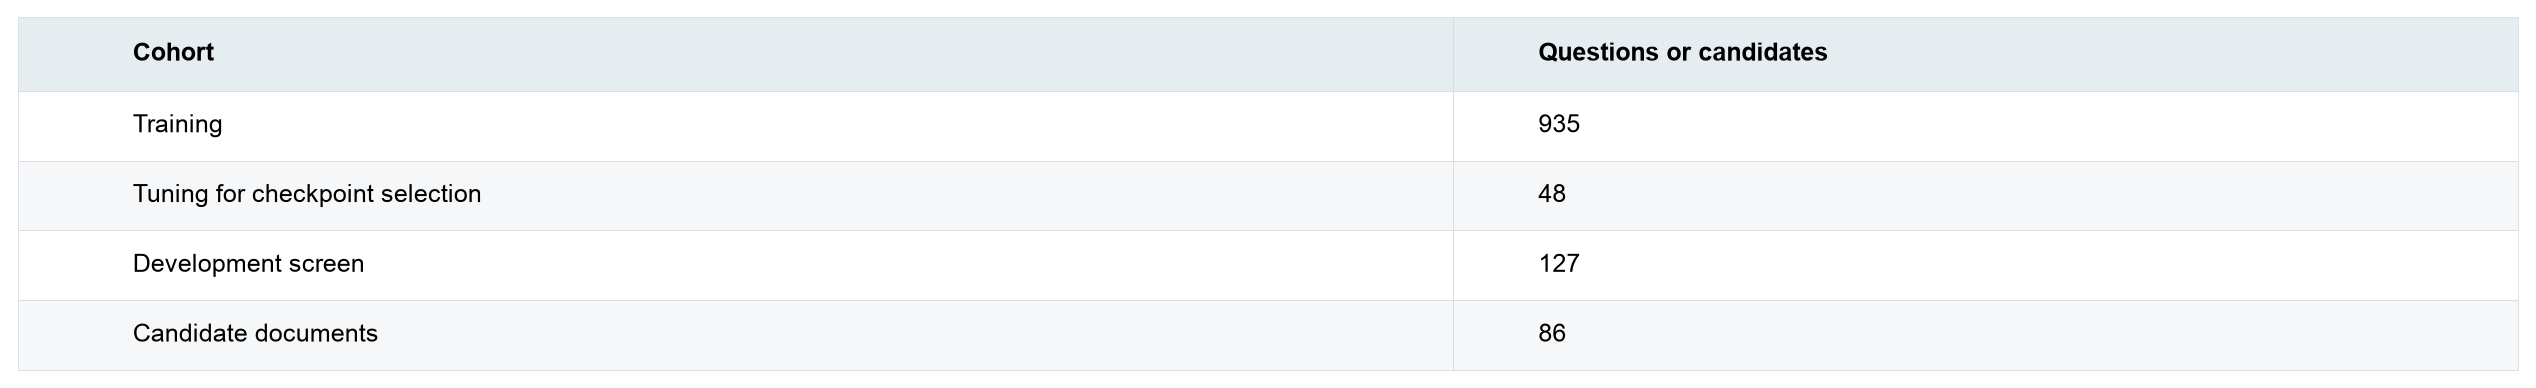

**Table 01 — Frozen cohorts and candidate documents.** Export: `graphs/stair_table_01.png`.

In [7]:
evidence = load_evidence(CFG.ROOT, CFG.RUNS, CFG.SEAL_HASHES)
start_publication(CFG.GRAPHS, CFG.ASSET_PLAN, CFG.img_dim1, CFG.export_dpi)
print(json.dumps(evidence['proof'], indent=2))
table([{'Cohort': k, 'Questions or candidates': len(evidence['data'][v])} for k, v in [('Training', 'train935'), ('Tuning for checkpoint selection', 'tune'), ('Development screen', 'screen'), ('Candidate documents', 'corpus')]])

The training pool has 935 questions; 48 separate tuning questions select checkpoints. All reported development metrics use the same 127 questions and 86 candidates. Seed 42 and the training order are shared. Three preflagged ambiguous screen questions define a separate 124-question sensitivity analysis; the primary denominator remains 127.

# Start by searching the text

The experiment retrieves a document label, not a generated answer. The mechanism is: question plus the declared catalogue → model-generated title → label-to-document lookup. A prefix trie can restrict decoding to legal titles, while preserving full-vocabulary probabilities; it does not decide which legal title is correct.

BM25 A sees source bodies; neural prompts contain questions and catalogues. That access difference limits causal claims about neural versus lexical methods.

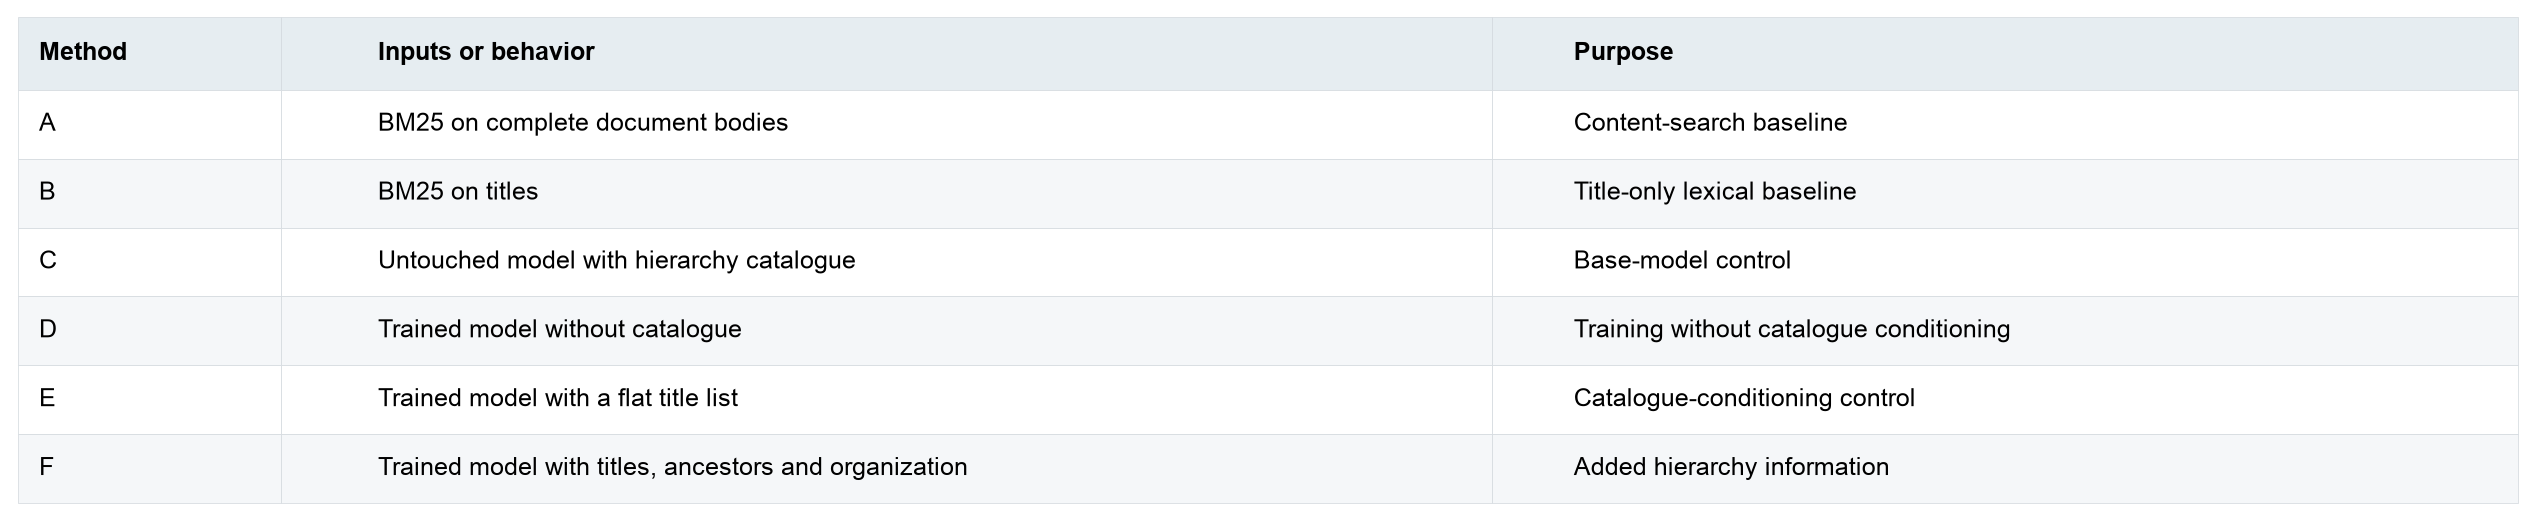

**Table 02 — Retrieval methods and their information.** Export: `graphs/stair_table_02.png`.

In [8]:
table([{'Method': m, 'Inputs or behavior': inputs, 'Purpose': purpose} for m, inputs, purpose in [('A', 'BM25 on complete document bodies', 'Content-search baseline'), ('B', 'BM25 on titles', 'Title-only lexical baseline'), ('C', 'Untouched model with hierarchy catalogue', 'Base-model control'), ('D', 'Trained model without catalogue', 'Training without catalogue conditioning'), ('E', 'Trained model with a flat title list', 'Catalogue-conditioning control'), ('F', 'Trained model with titles, ancestors and organization', 'Added hierarchy information')]])

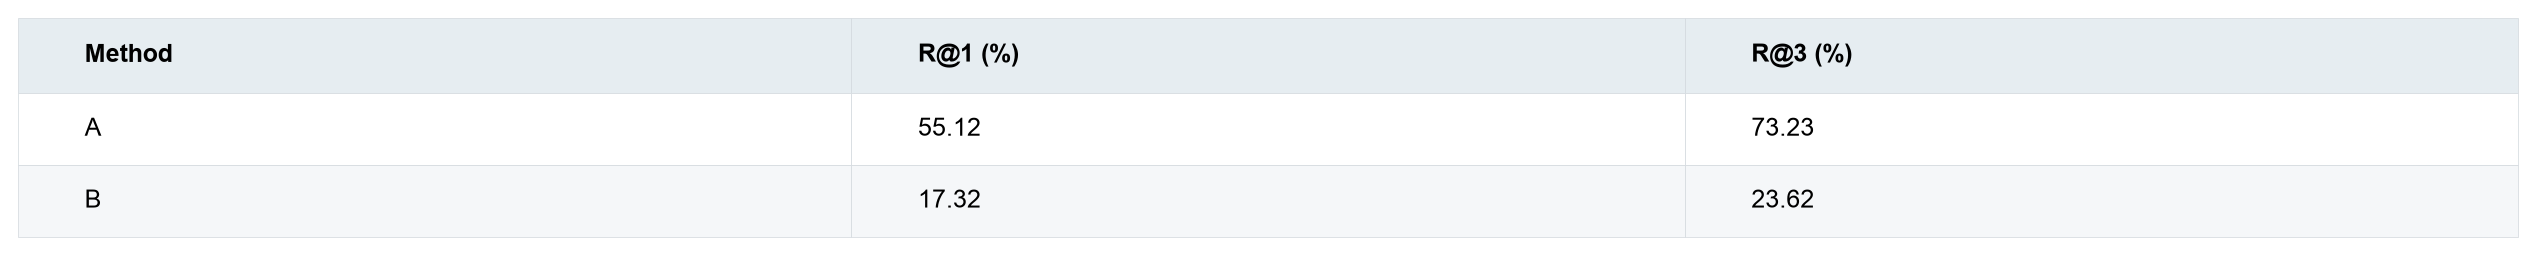

**Table 03 — Captured lexical baselines.** Export: `graphs/stair_table_03.png`.

In [9]:
table([{'Method': r['method'], 'R@1 (%)': 100*r['r1'], 'R@3 (%)': 100*r['r3']} for r in evidence['analysis']['metrics'] if r['family'] == 'lexical'])

The lexical controls were captured previously and are rescored here from their saved predictions. No fresh lexical or neural search is performed.

# Learn to return a section title

Both Qwen models use a frozen BF16 language backbone and FP32 rank-16/alpha-32 LoRA adapters, dropout zero, AdamW at learning rate 1e-4, effective batch eight and non-thinking, title-only prompts. Each D/E/F fit completed 384 optimizer updates. Checkpoint selection takes the earliest best tuning Recall@1 every 32 updates, separately within 128- and 384-update search budgets.

The 4B microbatch is one with accumulation eight; 2B admitted four with accumulation two. Larger 4B microbatches failed catalogue-gradient parity and were rejected. Depth, width, pretrained weights, adapter dimensions and admitted numeric layout differ, so this is a practical model upgrade rather than a causal parameter-count experiment. The matched FLAN controls retain their separate CPU/full-fine-tuning recipe.

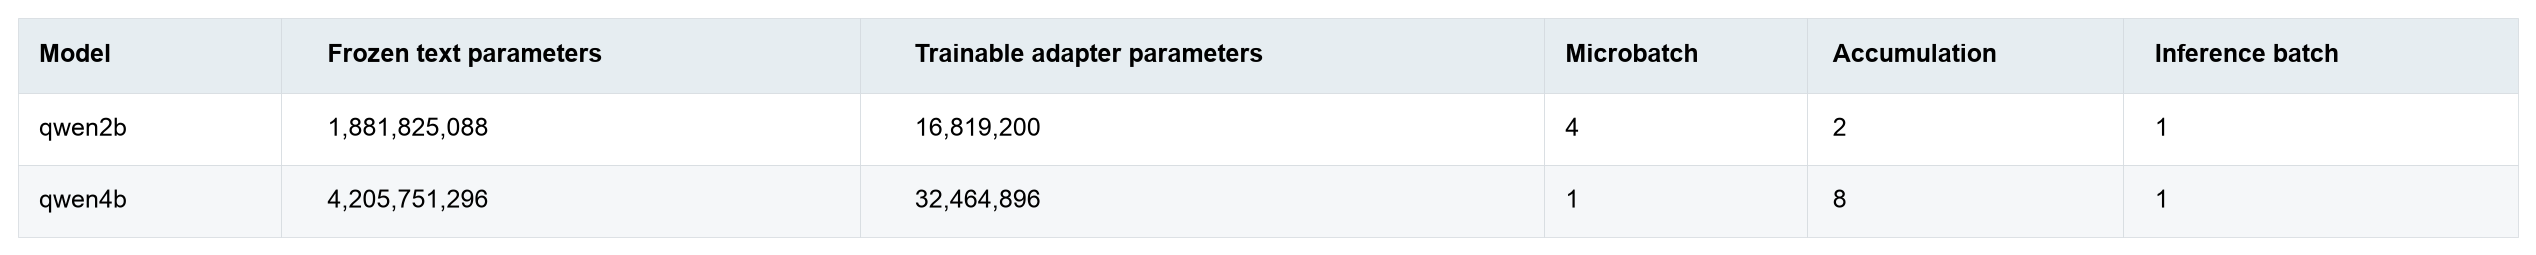

**Table 04 — Loaded model sizes and admitted batches.** Export: `graphs/stair_table_04.png`.

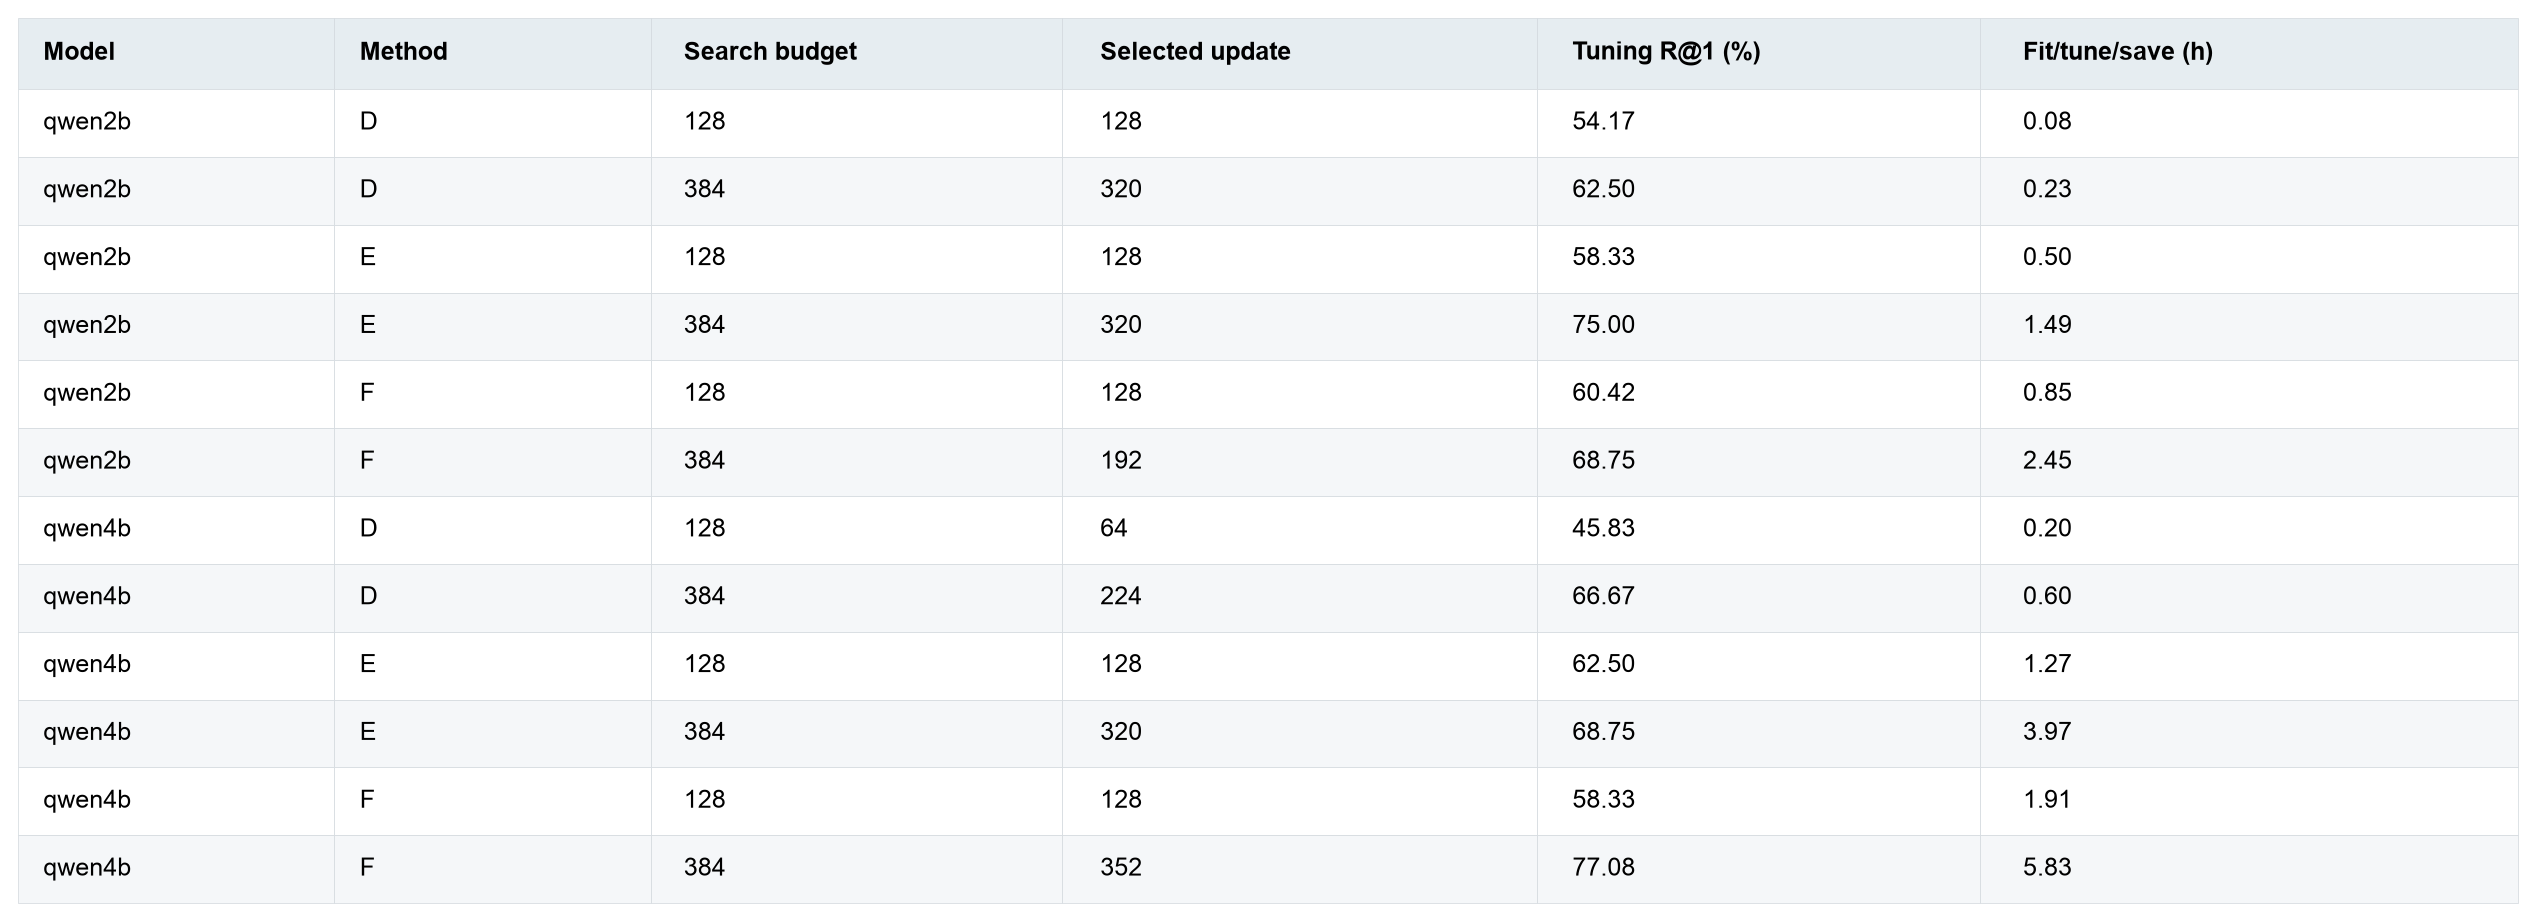

**Table 05 — Selected checkpoints and search costs.** Export: `graphs/stair_table_05.png`.

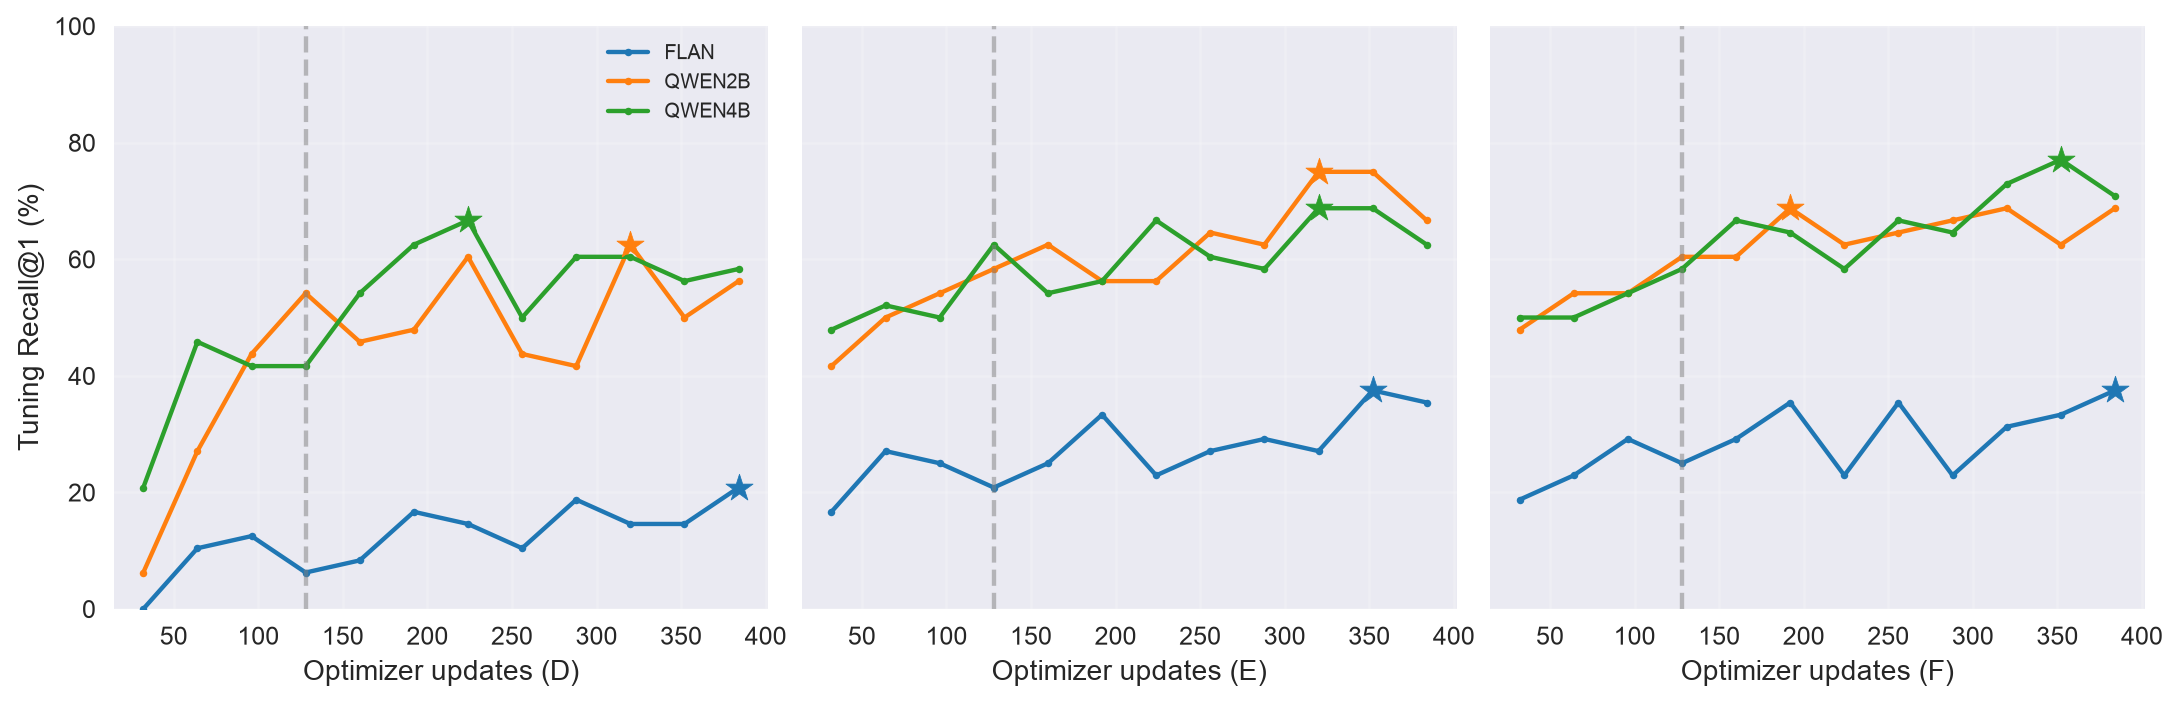

**Graph 06 — Captured tuning curves.** Export: `graphs/stair_graph_06.png`.

In [10]:
table([{'Model': family, 'Frozen text parameters': evidence['models'][family]['base_parameters'], 'Trainable adapter parameters': evidence['models'][family]['adapter_parameters'], 'Microbatch': contract['training_microbatch'], 'Accumulation': contract['accumulation'], 'Inference batch': contract['inference_batch']} for family, contract in evidence['contracts'].items()])
table(evidence['selections'])
tuning_figure(evidence)

**Figure 06 Notes:** Stars indicate earliest best checkpoints selected during tuning within the 384-update budget (D224, E320, F352 for 4B).

# Give the model the table of contents

The primary comparison evaluates **4B E versus 2B E at the 384-update search budget** using constrained Recall@1, testing whether the flat catalogue benefits from larger model capacity.

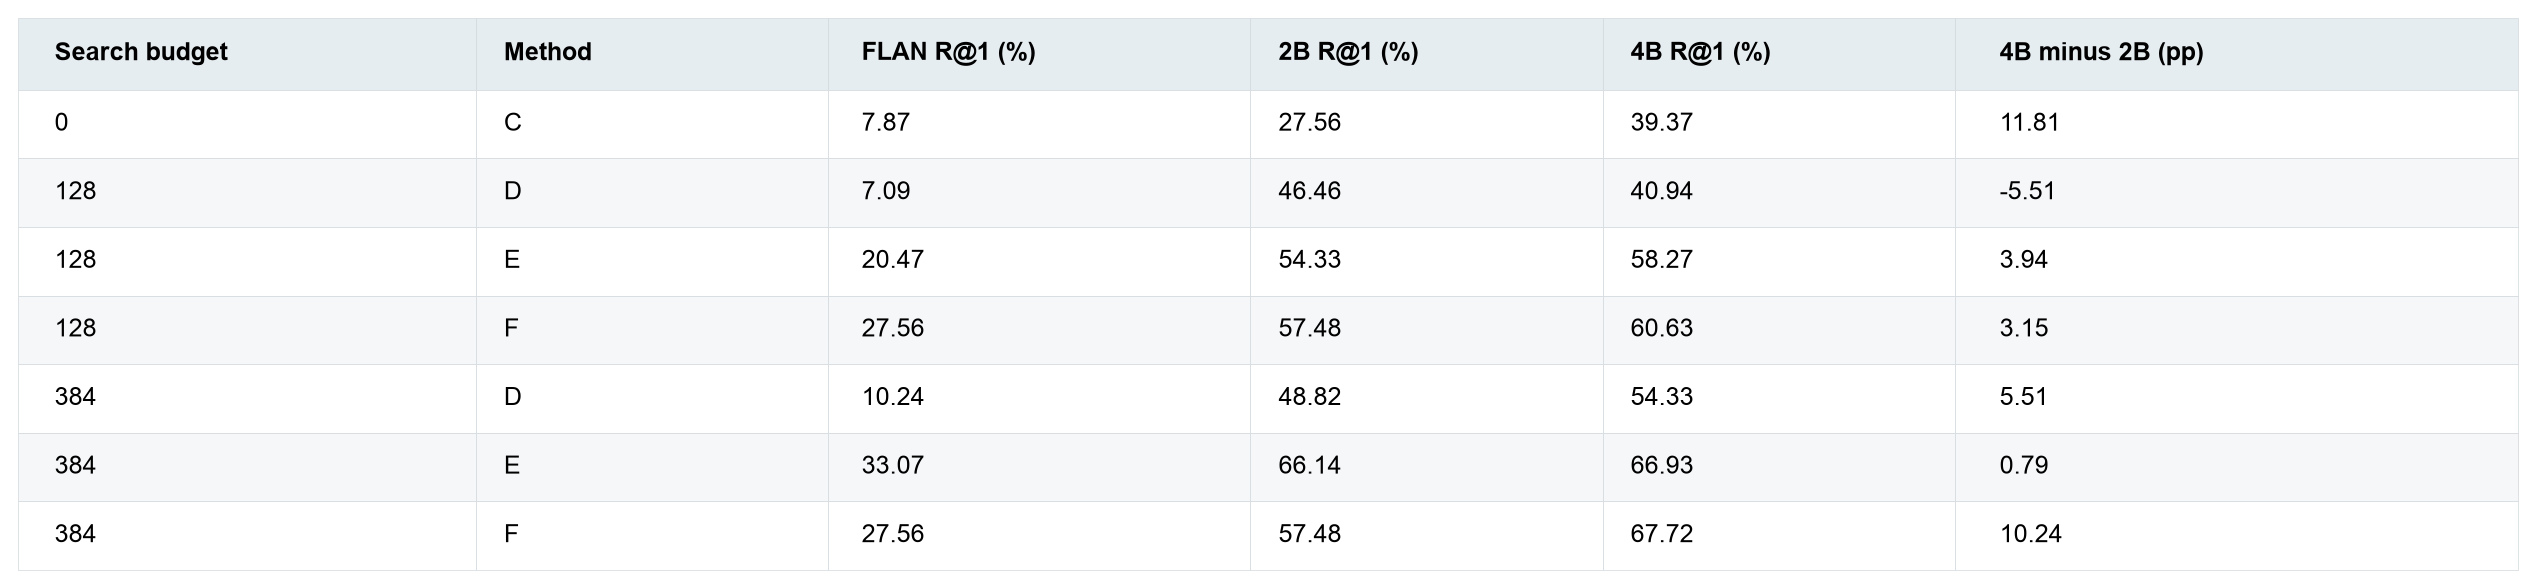

**Table 07 — Matched development Recall at rank one.** Export: `graphs/stair_table_07.png`.

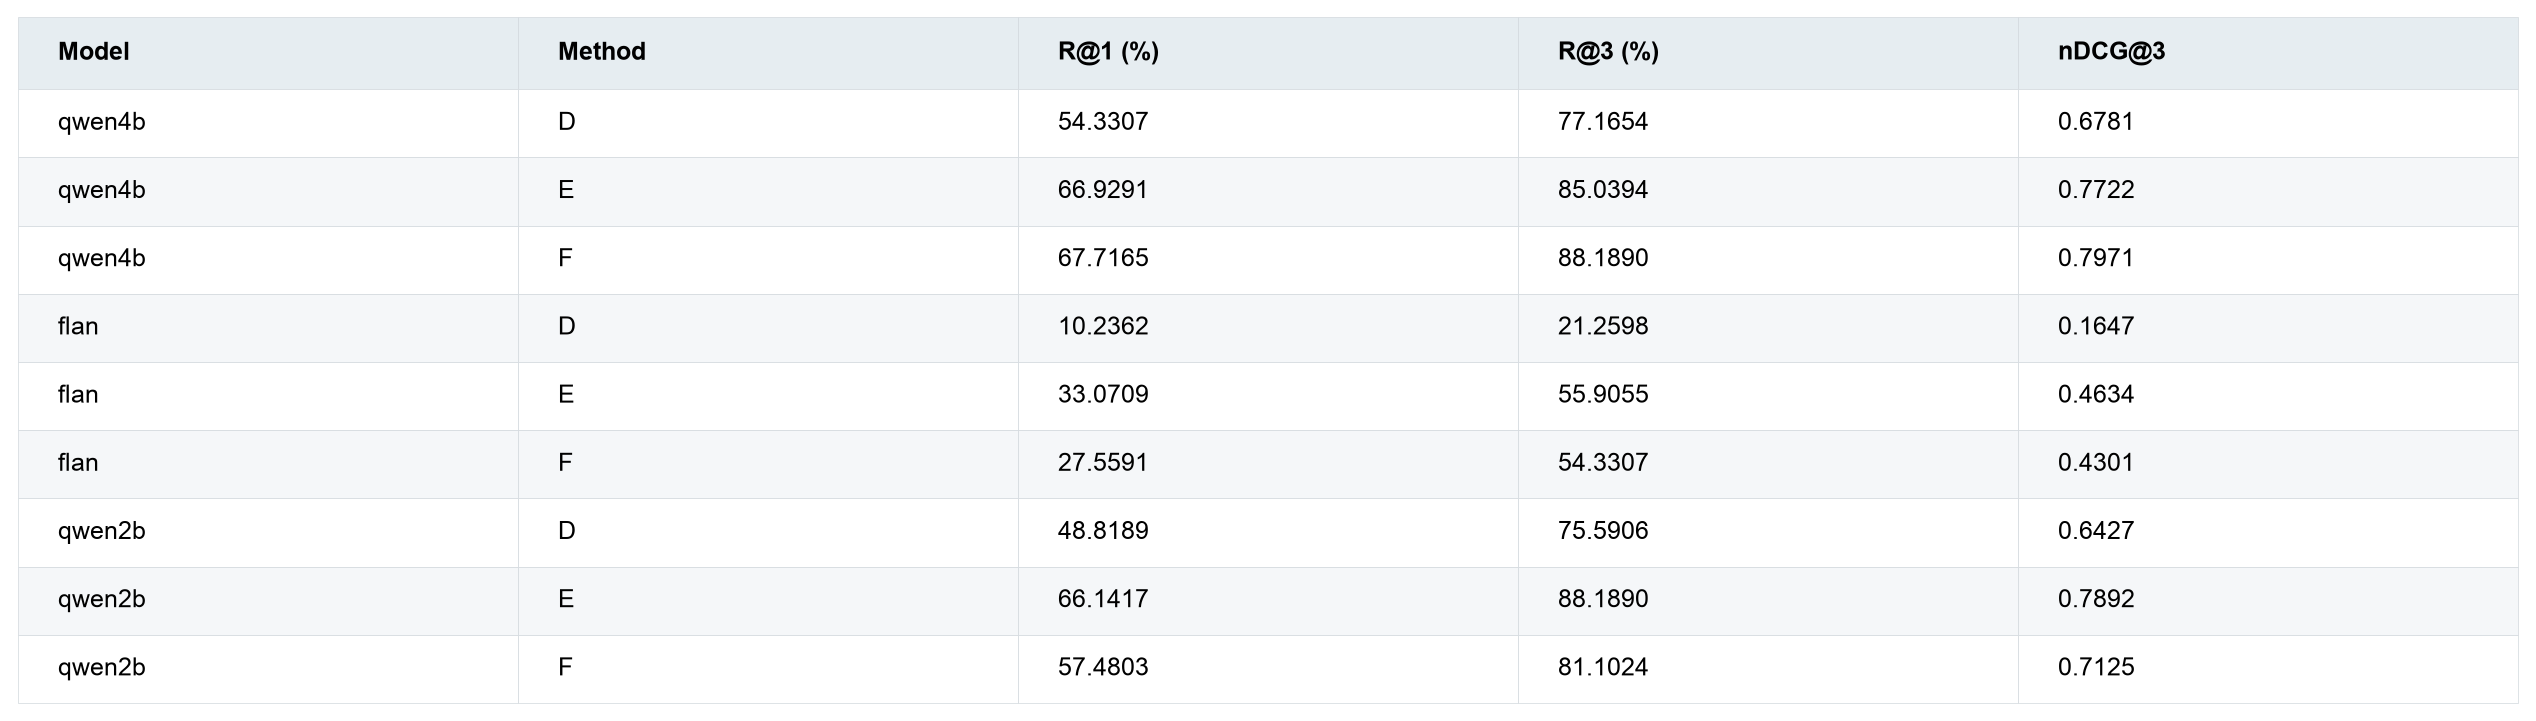

**Table 08 — Full-budget rank metrics.** Export: `graphs/stair_table_08.png`.

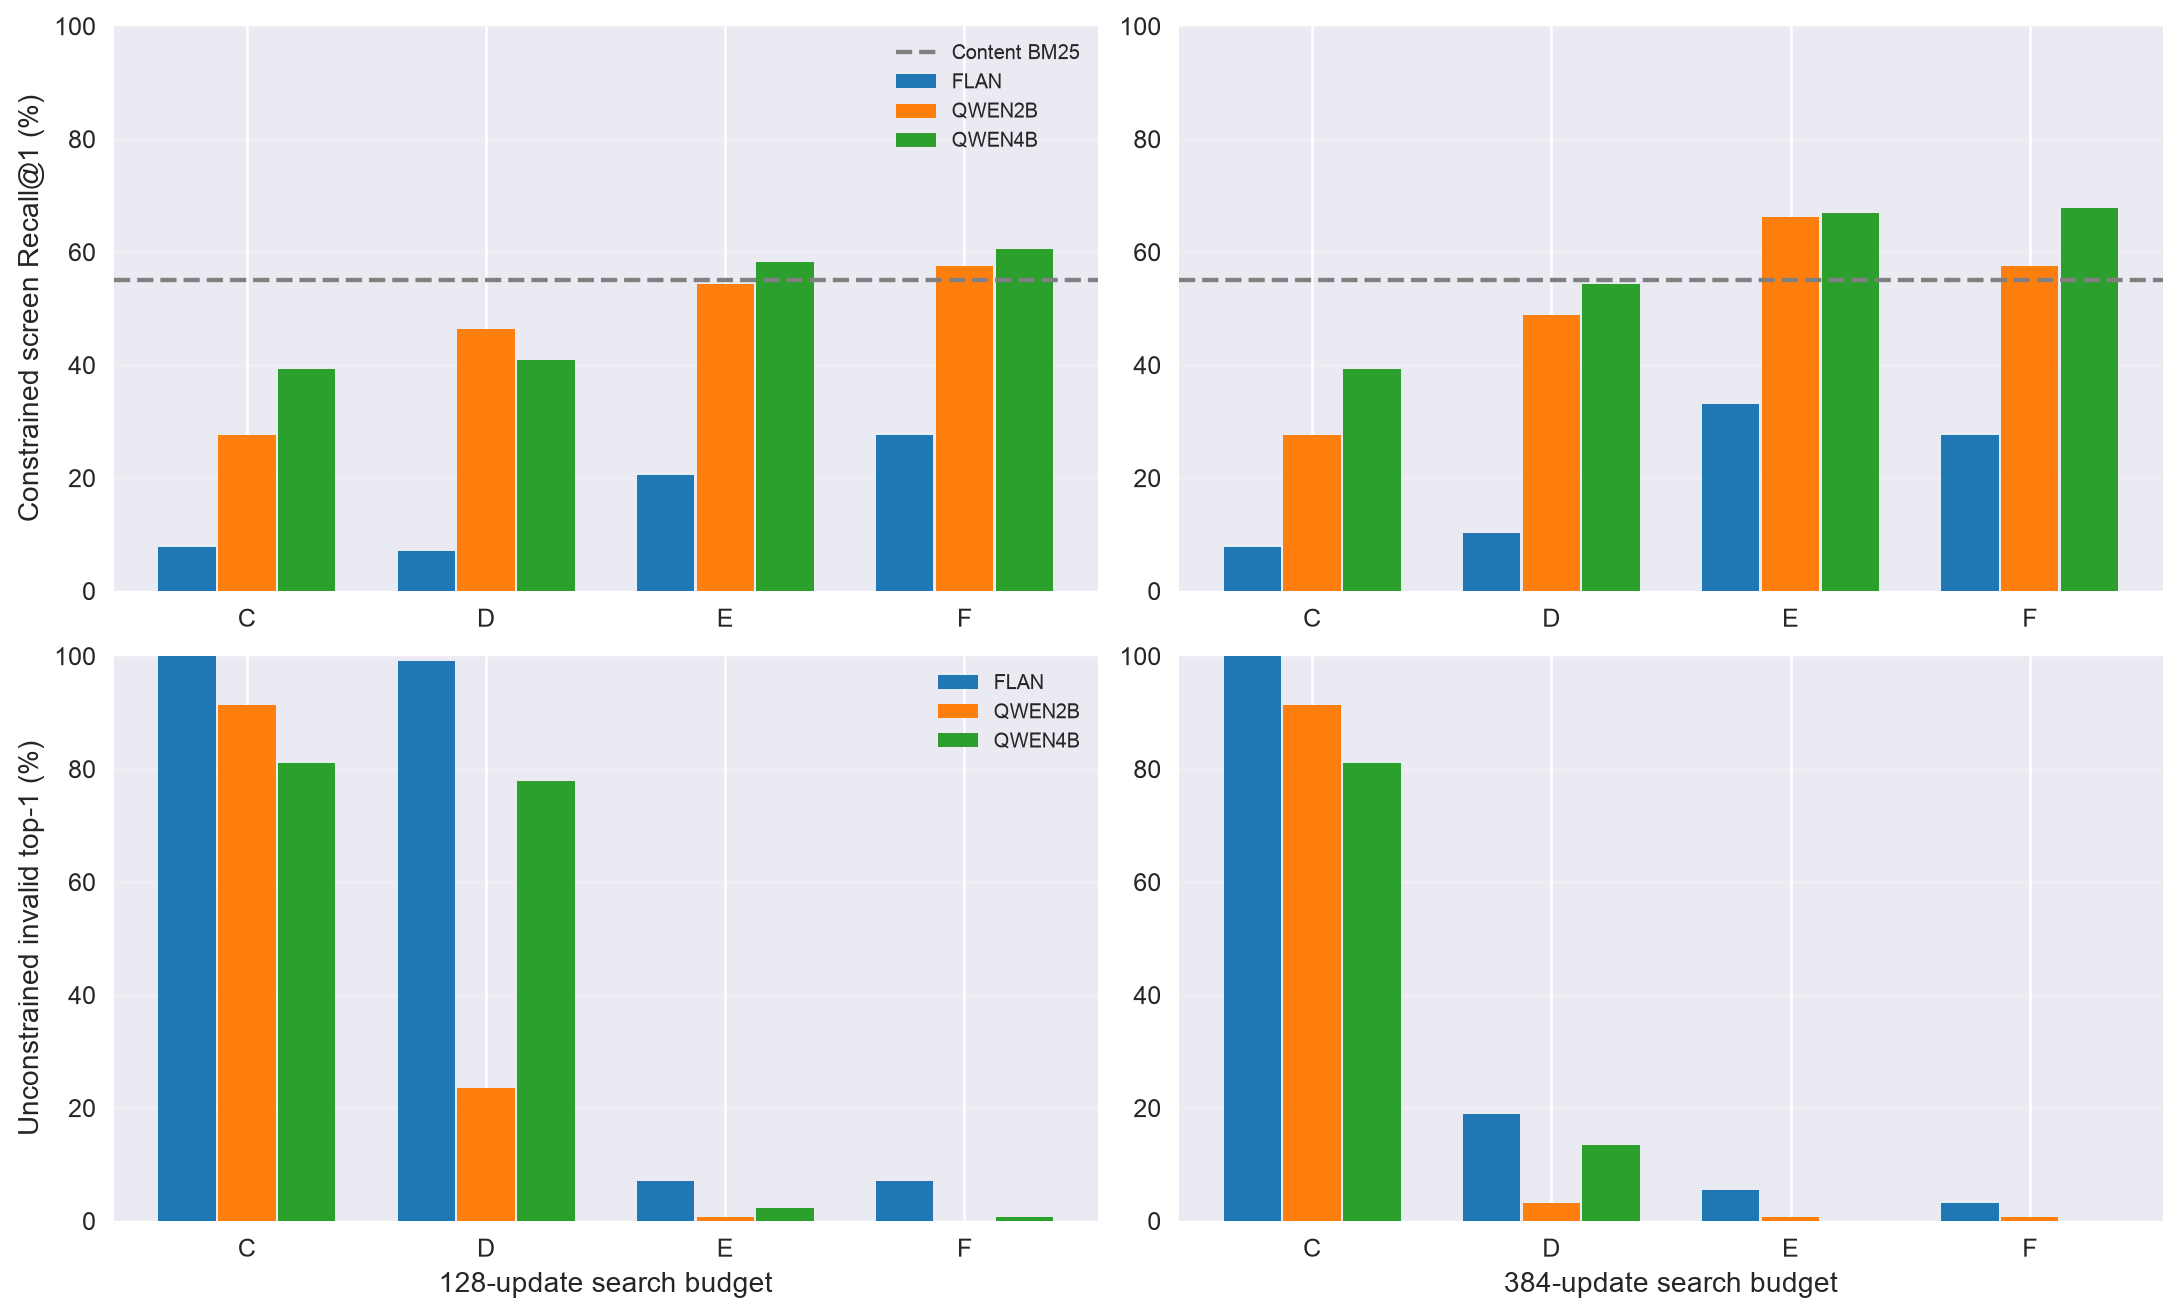

**Graph 09 — Matched accuracy and unconstrained invalidity.** Export: `graphs/stair_graph_09.png`.

In [11]:
accuracy_table(evidence)
rank_table(evidence)
comparison_figure(evidence)

**Figure 09 Notes:** Comparison across FLAN (blue), 2B (orange), and 4B (green) with dashed content BM25 baseline. At the full 384-update budget, Method E Recall@1 shifts from 66.14% to 66.93% (a one-question difference). Method F reaches 67.72%, exceeding 4B E by one question.

# A valid title can still be wrong

Constrained legality is guaranteed by the trie. Learned format adherence is assessed separately by unconstrained decoding. A title can be legal yet retrieve the wrong document, and a correctly retrieved document can contain multiple source sections.

Invalid hypotheses receive no relevance while keeping their rank positions. Removing invalid or duplicate outputs would change the metric and is not done here.

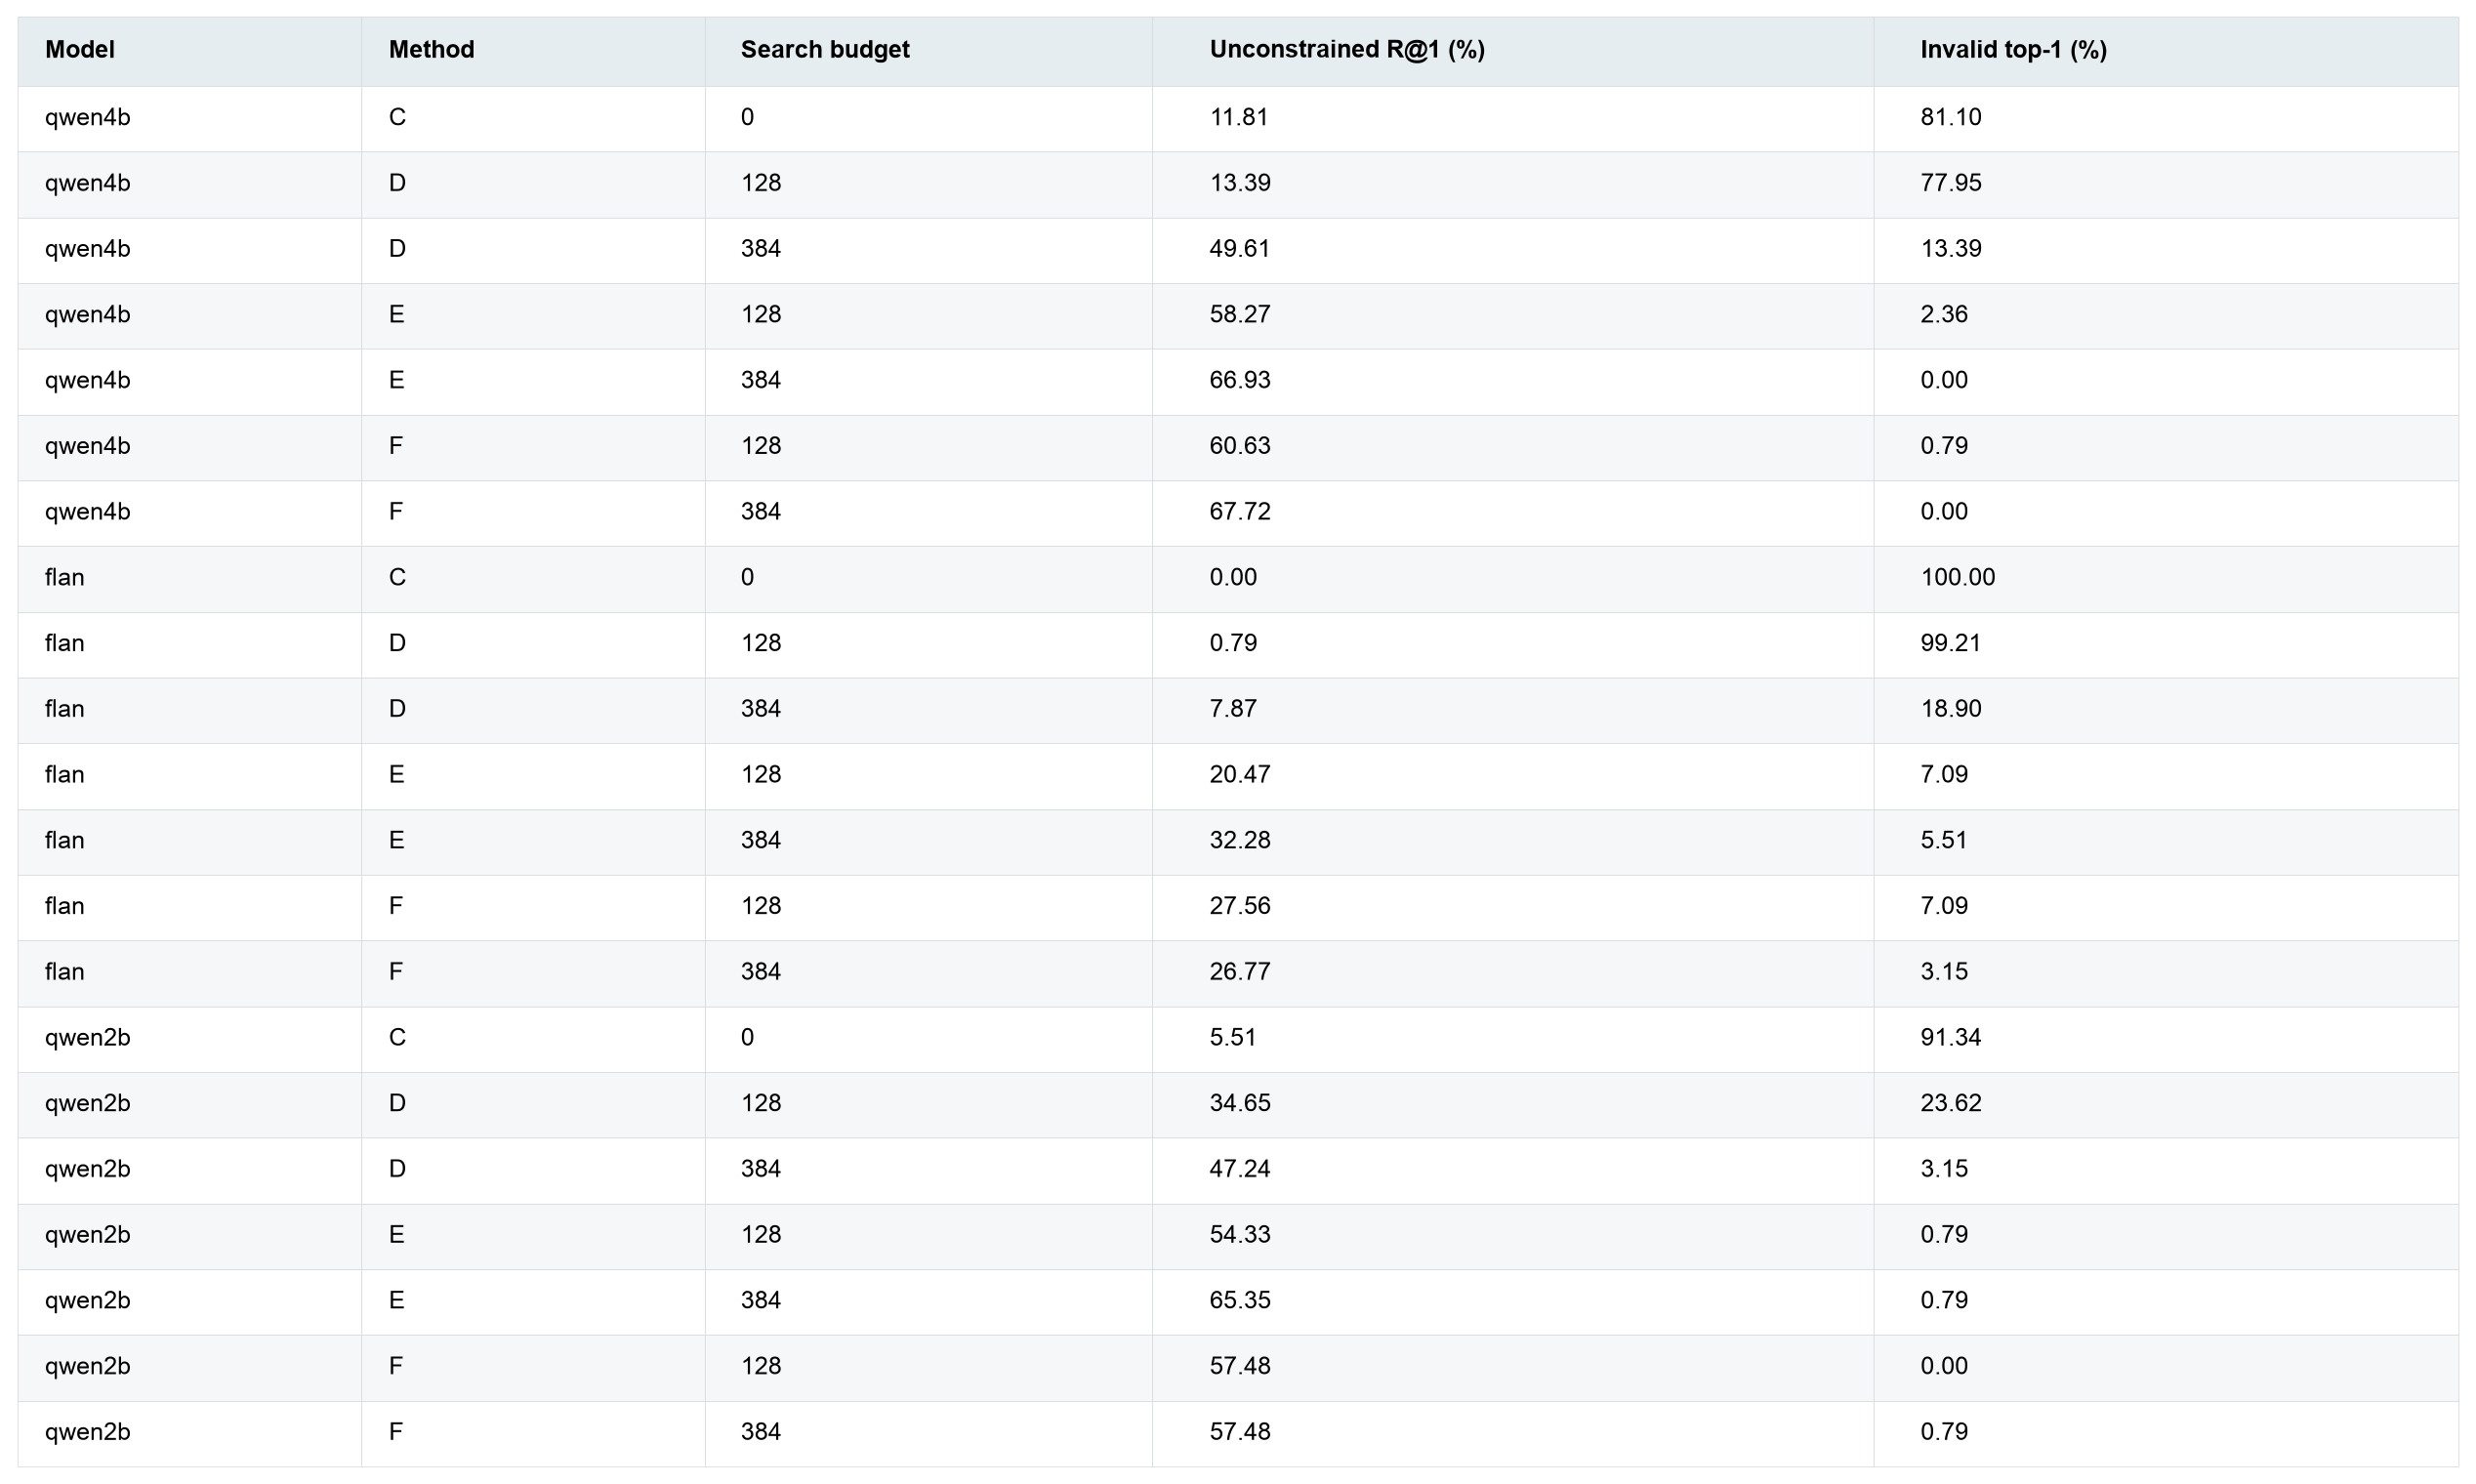

**Table 10 — Unconstrained title validity.** Export: `graphs/stair_table_10.png`.

In [12]:
validity_table(evidence)

At the full search budget, E and F have zero invalid top-1 titles in this 127-question 4B sample. That does not establish a zero population error rate. D has appreciable unconstrained invalidity, and the short-budget 4B D selection uses only 512 distinct training questions; the exposure/selection tables explain this difference.

# Count the gains and the losses

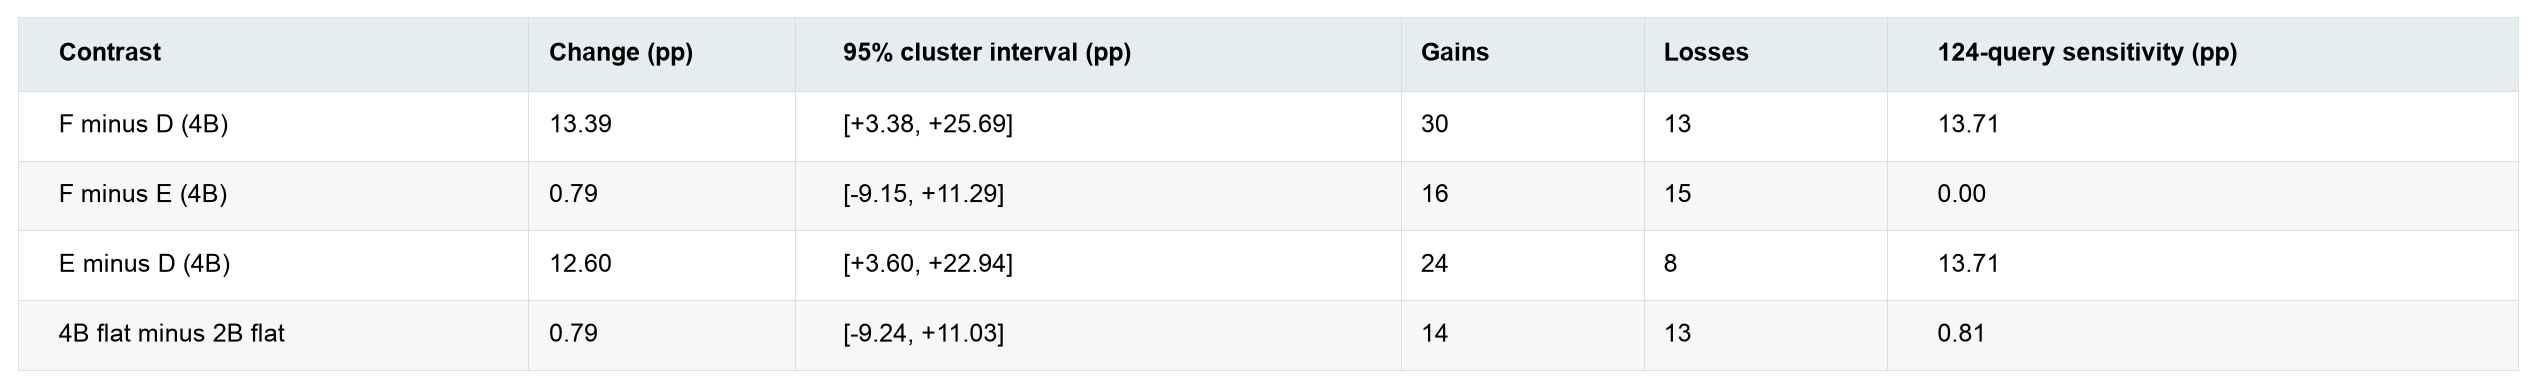

**Table 11 — Paired effects and ambiguity sensitivity.** Export: `graphs/stair_table_11.png`.

In [13]:
effect_table(evidence)

The primary 4B-minus-2B flat-catalogue effect is **+0.79 pp**, with an exploratory 95% cluster interval **[-9.24, +11.03]**. There are 14 gains and 13 losses across the same questions; net accuracy alone hides that turnover.

At the full budget, 4B E–D is +12.60 pp and F–D is +13.39 pp: catalogue conditioning helps this local task. F–E is only +0.79 pp, with interval [-9.15, +11.29], and becomes **0.00 pp** in the fixed ambiguity sensitivity analysis. These results do not establish an additional hierarchy benefit. The intervals cover released-document sampling conditional on one book/seed; secondary comparisons are not multiplicity-adjusted confirmation tests.

# What happens to rarely trained sections

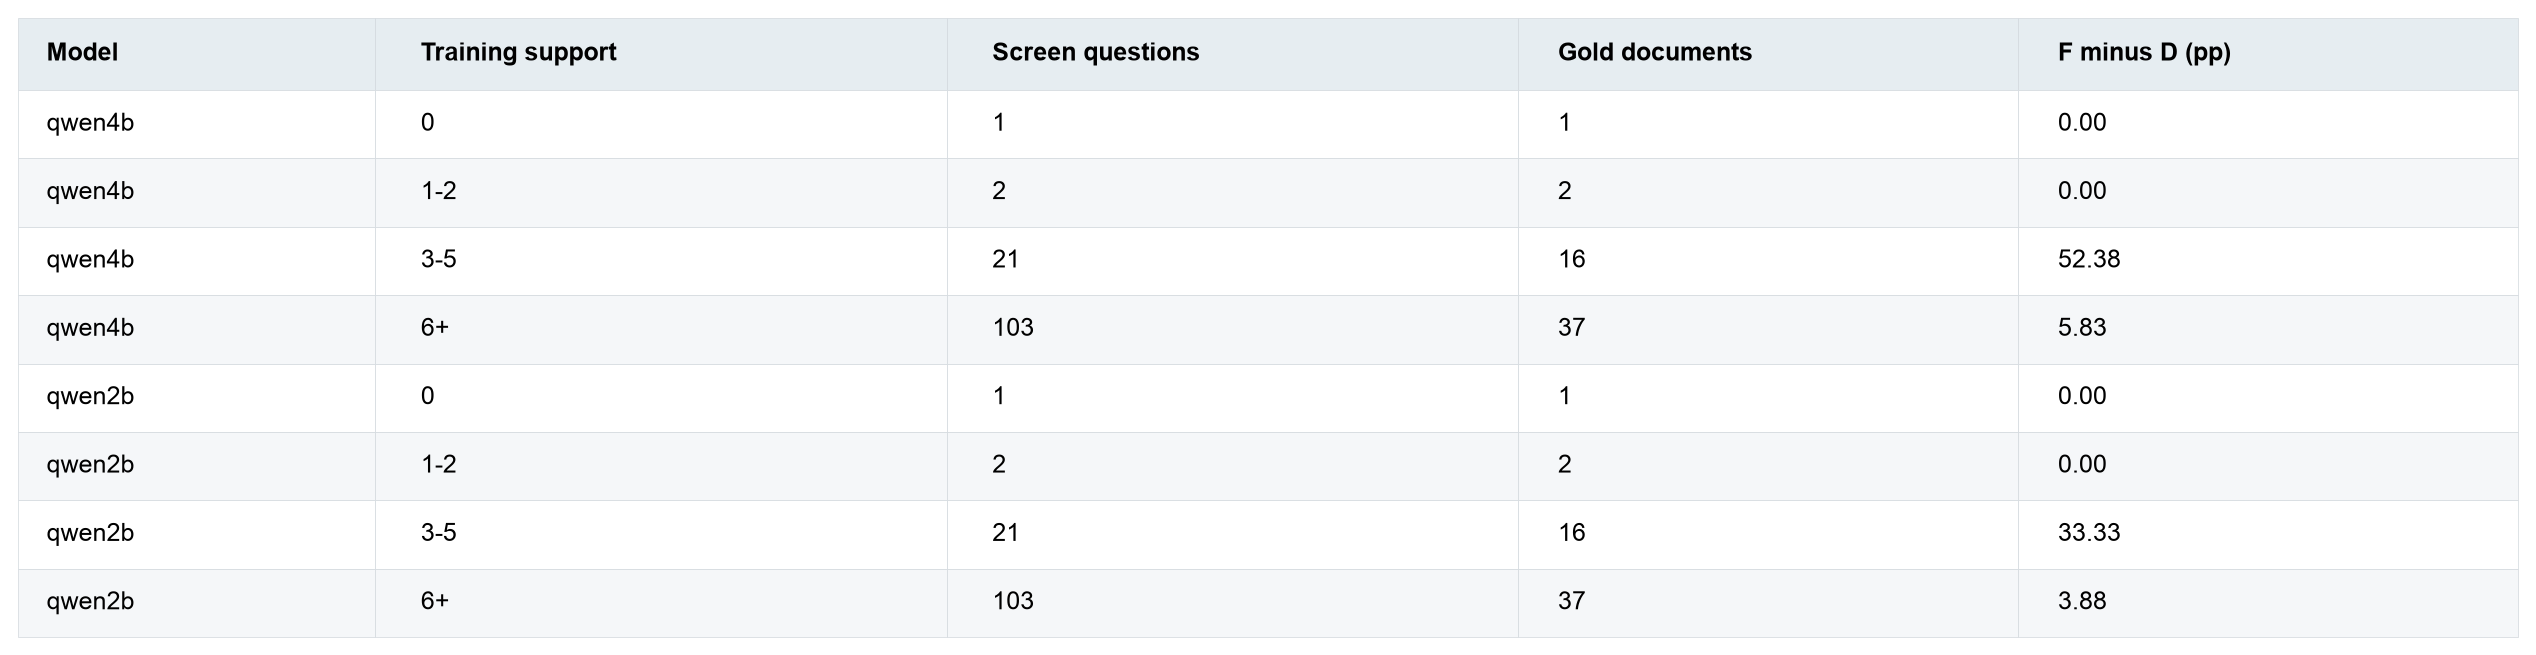

**Table 12 — Training support and catalogue conditioning.** Export: `graphs/stair_table_12.png`.

In [14]:
table([{'Model': r['family'], 'Training support': r['bin'], 'Screen questions': r['paired']['queries'] if r['paired'] else 0, 'Gold documents': r['paired']['document_clusters'] if r['paired'] else 0, 'F minus D (pp)': r['paired']['difference_pp'] if r['paired'] else None} for r in evidence['analysis']['low_support_F_minus_D'] if r['budget'] == 384 and r['mode'] == 'constrained' and r['family'] in ['qwen2b', 'qwen4b']])

Only three screen questions are in the zero or one-to-two training-example groups. Neither model establishes a hierarchy advantage there. A positive F–D effect in the 3–5 group is descriptive; it does not confirm the paper's broader rare-document claim. Support bins use the common full training pool, while selected-checkpoint exposure is recorded separately.

# Cost, failures and what remains uncertain

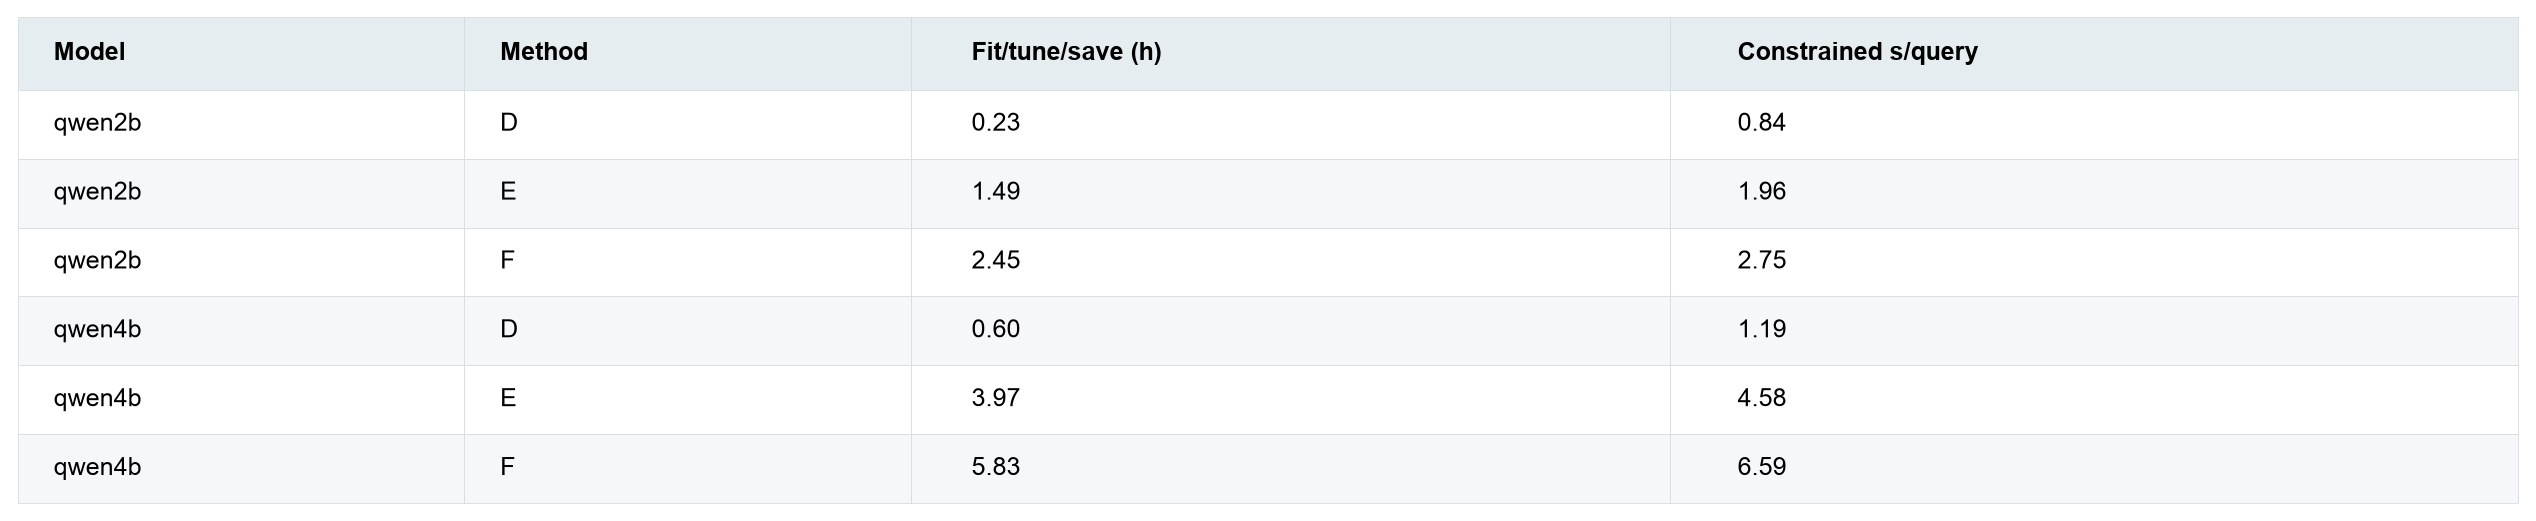

**Table 13 — Full-budget search and constrained inference costs.** Export: `graphs/stair_table_13.png`.

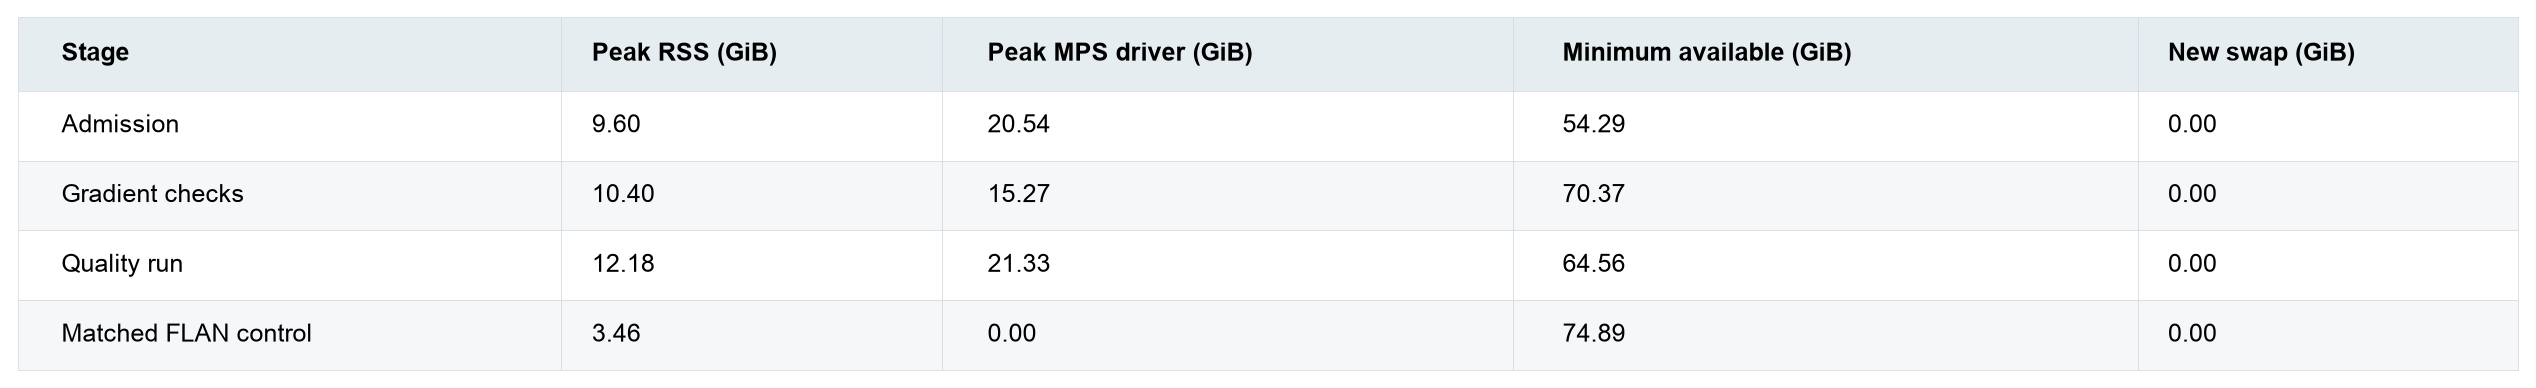

**Table 14 — Captured resource counters.** Export: `graphs/stair_table_14.png`.

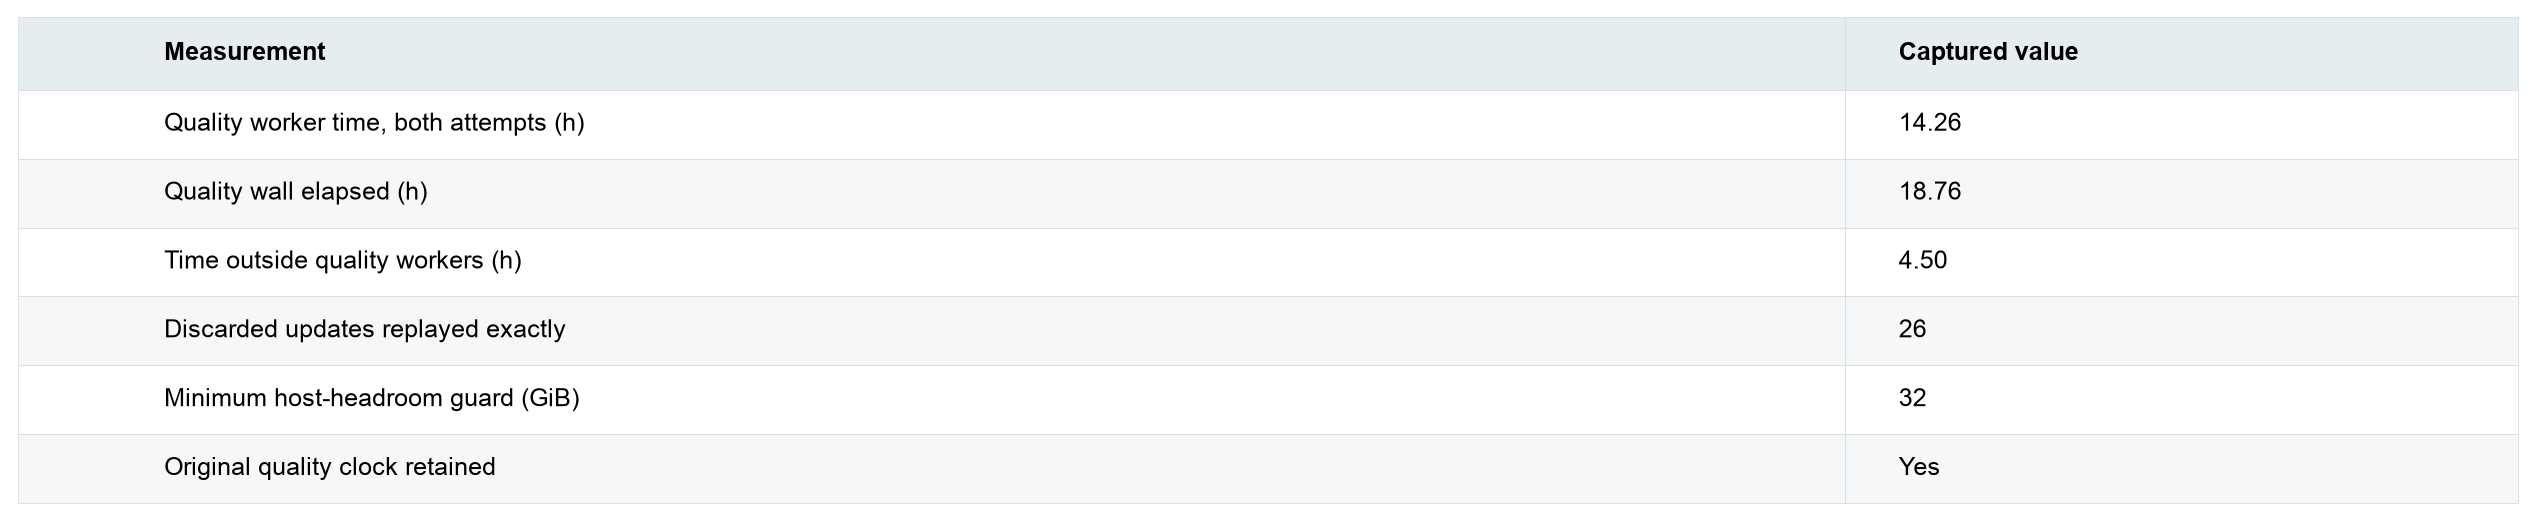

**Table 15 — Memory interruption and exact recovery.** Export: `graphs/stair_table_15.png`.

In [15]:
table(evidence['costs'])
resource_table(evidence)
recovery_table(evidence)

The three full D/E/F fit/tune/save searches cost **10.41 hours for 4B versus 4.17 for 2B (2.49×)**. Quality workers across the two 4B attempts used 14.26 hours; quality wall elapsed was 18.76 hours, including 4.50 hours outside those workers. Download, admission and authoring are separate costs. Replay here measures none of those model speeds anew.

The remaining-memory guard stopped the first quality attempt after D346 while an external IDE process reported about 72 GiB RSS. After host memory was freed, recovery restored D320 adapter/optimizer/RNG state and exactly reproduced all 26 discarded updates' losses and gradient norms. The source attempt and discarded work remain in the evidence. The original 24-hour quality clock was retained.

The **32 GiB guard is minimum remaining host memory**, with separate 48 GiB RSS/driver ceilings and 1 GiB maximum new swap. It is not a 32 GiB model allocation cap. The completed quality run peaked at 21.33 GiB MPS-driver allocation and 12.18 GiB RSS with no new swap. Those counters overlap and must not be added. This demonstrates **4B LoRA**, not full-parameter 4B training, on this Mac.

The earlier admission also hit the host-memory floor during a second full-model load. The revised lifecycle keeps one resident base per worker; independent fresh-process reload and selected-checkpoint parity checks preserve correctness. This resource failure is separate from the original section-boundary failure.

# Closing time

In [16]:
display(Markdown(conclusion(evidence)))
finish_publication(evidence)
print('Verified report files:', len(evidence['consumed_files']))
print('Original numerical validation:', evidence['validation']['status'])
assert all(evidence['stages'][str(i)]['status'] == 'complete' for i in range(1, 7))
assert evidence['proof']['new_model_inference_calls'] == evidence['proof']['new_training_updates'] == 0

The flat-catalogue upgrade changes Recall@1 by **+0.79 percentage points**, with an exploratory 95% interval **[-9.24, +11.03]**. The hierarchy's point advantage over 4B flat is +0.79 points and +0.00 after the fixed ambiguity sensitivity check. The D/E/F search cost rises from 4.17 to 10.41 hours (2.49×). **Keep 2B flat as the practical reference for now.** This is a development-screen decision from one book and one seed. The 240-question reserve is unscored.

Exported 15 numbered PNGs to /private/tmp/stair-current-report-d5_uugyo/graphs
Verified report files: 62
Original numerical validation: passed


The best observed 4B recipe answers only two more development questions correctly than 2B flat. The primary flat-catalogue upgrade is inconclusive, and the hierarchy-specific point advantage is fragile. **4B is feasible, but this pilot does not justify replacing 2B flat on cost grounds.** A larger model, a useful catalogue and an additional hierarchy effect are separate questions.

This is a local adaptation, not a replication of the paper's Mistral benchmark. It uses one book, one seed, repeated development screening, externally generated labels and document anchors with unresolved source-boundary ambiguity. The 240-question reserve is unscored; additional seeds and final confirmation have not been run.

Full captured analysis: [4B pilot report](docs/stair-qwen35-4b-pilot.md), [2B pilot report](docs/stair-qwen35-2b-pilot.md), and [source-boundary decision](docs/stair-section-boundary-decision.md). Historical notebook: [original FLAN study](stair_local_demo.ipynb). Companion draft: [post.md](post.md), using the same numbered PNG filenames. This update preserves the sealed numerical experiments and the historical post outline.

Attribution: SearchTome (`meghanadh/SearchTome`), revision `48d3b3545950b3857dc3657fb22e4b79b8ed8df5`, CC BY-SA 4.0; Christine Jonick, *Principles of Financial Accounting*, University of North Georgia Press (2017), attributing the University System of Georgia. Retain source copyright exceptions. FLAN-T5-small model card: Apache-2.0. Qwen3.5-2B and Qwen3.5-4B model cards: Apache-2.0. Model/source manifests retain the pinned revisions and hashes.